In [7]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
from scipy.signal import butter, filtfilt
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '0'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
import tensorflow as tf
import keras
from keras import layers, Model
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import qmc
import joblib
import json
import gc
import textwrap
from PIL import Image as PILImage
from reportlab.lib.units import cm
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import Paragraph, Image, PageBreak, SimpleDocTemplate


def set_seed(seed):
    keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

### Dados (mesma montagem do scriptPMG_refactored_pinn)
`make_df('')` = trechos A–D de aceleração nivelada do voo 039; `make_df('completo')` = voos 039–042 inteiros (A–D). Nos dois casos, B é validação/teste.

In [8]:
def def_parametros():
    parametros = [
            "TIME",        "TEMPO_SAD",        "EVENTO",        "HH",        "MM",        "SS",        "MSS",        "TOT",        "ALFAG",        "BETAG",
            "DL",        "DM",        "DN",        "DF",        "NX",        "NY",        "NZ",        "P",        "Q",        "R",        "PB",        "PB1",
            "QB",        "QB1",        "TI",        "T5_C",        "TETAL",        "FIL",        "CID",        "NG",        "PSI",        "PBEX",        "PIX",
            "PIY",        "VB",        "VB1",        "ZPB",        "ZPB1",        "W",        "pa",        "qc",        "Zp",        "Vc",        "Mach",
            "Ta_C",        "Va",        "Alfa",        "Beta",        "Ta_K",        "T",        "No. OBS."
    ]
    return parametros

In [9]:
def butter_lowpass(signal, cutoff_period_s, fs=1.0, order=1):
    cutoff_freq = 1.0 / cutoff_period_s
    nyq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

In [10]:
def parametros_adicionais(df):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Pa0 = 1013.25
    df['delta'] = df['pa']/Pa0
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    df['Mach2'] = df['Mach']**2

    df['Va2'] = df['Va']**2

    S = 19.3

    df['NX_filtered'] = butter_lowpass(df['NX'], cutoff_period_s=15)
    df['NZ_filtered'] = butter_lowpass(df['NZ'], cutoff_period_s=15)
    df['Alfa_filtered'] = butter_lowpass(df['Alfa'], cutoff_period_s=30)
    df['Va_filtered'] = butter_lowpass(df['Va'], cutoff_period_s=30)
    df['Hdot'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))*df['Va_filtered'] # Hdot em m/s
    df['Hdot_V'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))

    df['Hdot_W_V_dlt'] = (df['NX']*np.cos(np.radians(df['Alfa'])) + df['NZ']*np.sin(np.radians(df['Alfa'])))*df['W']/df['delta'] # (Hdot/V) * (W/delta), em kgf

    df['NZ_W_dlt'] = df['NZ']*df['W']/df['delta']
    df['NZ_W_dlt_sqr'] = df['NZ_W_dlt']**2

    # Filtro para cortar dados irrelevantes:
    df = df[df['Va_filtered'] > 90]
    df = df[df['Zp'] > 3000]

    return df

In [11]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
    else:
        files = ['039_2013_VIN_FND']

    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
    parametros = def_parametros()
    all_dfs = []
    for file in files:
        data = loadmat(local + file + '.mat')
        df = pd.DataFrame(data['DADOS'])
        df.columns = parametros
        df['filename'] = file
        all_dfs.append(df)
    df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df)

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['filename'].str.contains('039'), 'faixa_altitude'] = 'A'
        df.loc[df['filename'].str.contains('040'), 'faixa_altitude'] = 'B'
        df.loc[df['filename'].str.contains('041'), 'faixa_altitude'] = 'C'
        df.loc[df['filename'].str.contains('042'), 'faixa_altitude'] = 'D'
    else:
        df.loc[(df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 52625), 'faixa_altitude'] = 'A'
        df.loc[(df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53200), 'faixa_altitude'] = 'B'
        df.loc[(df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54073), 'faixa_altitude'] = 'C'
        df.loc[(df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55100), 'faixa_altitude'] = 'D'
        df = df[df['faixa_altitude'].notna()].copy()

    return df

In [12]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [13]:
G0    = 9.80665     # m/s²
S_ASA = 19.3        # m²
P0_PA = 101325.0    # Pa (1013,25 mbar)


def adicionar_colunas_tracao_arrasto(df):
    """Features/targets desta análise que não vêm prontos do .mat (convenção do scriptPMG_refactored_pinn):
      Tn_dlt = T·cos(α)/δ  [kgf]                      -> equivalente físico de Z1
      D_dlt  = Tn_dlt − (Ḣ/V)·(W/δ)  [kgf]  (eq. 4.2)   -> equivalente físico de Z2
      CL = NZ·W/(q·S)  (eq. 3.1)   e   CD = D/(q·S),  com q = 0,7·p·M²  (não depende da unidade de Va).
    Hipótese: W em kgf, a mesma do comentário de Hdot_W_V_dlt. A célula de verificação compara CL e CD
    com os da planilha de aceleração nivelada."""
    df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
    df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']
    q_dlt = 0.7 * P0_PA * df['Mach'] ** 2                          # q/δ [Pa]
    df['CL'] = df['NZ'] * df['W'] / df['delta'] * G0 / (q_dlt * S_ASA)
    df['CD'] = df['D_dlt'] * G0 / (q_dlt * S_ASA)
    return df


_cache_df_base = {}

def obter_df_base(tipo_dados):
    """make_df(tipo_dados) + colunas de T/D + split, montado uma única vez por tipo de dados
    (o split é determinístico). Reexecute esta célula se make_df ou split_train_test_val mudarem."""
    if tipo_dados not in _cache_df_base:
        df = make_df(tipo_dados).copy()
        df = adicionar_colunas_tracao_arrasto(df)
        _cache_df_base[tipo_dados] = split_train_test_val(df)
    return _cache_df_base[tipo_dados].copy()


_avisos_descarte = set()

def preparar_df(tipo_dados, ramos):
    """df base sem as linhas com NaN/inf em alguma feature ou target da abordagem
    (ex.: T sem valor do thrust deck em parte do voo completo)."""
    df = obter_df_base(tipo_dados)
    cols = list(dict.fromkeys(c for r in ramos for c in r['features'] + r['targets']))
    validas = np.isfinite(df[cols].to_numpy(dtype=float)).all(axis=1)
    chave_aviso = (tipo_dados, tuple(cols))
    if not validas.all() and chave_aviso not in _avisos_descarte:
        _avisos_descarte.add(chave_aviso)
        por_tipo = df.loc[~validas, 'type'].value_counts().to_dict()
        print(f'[dados] {int((~validas).sum())} linhas descartadas por NaN/inf em {cols}: {por_tipo}')
    df = df[validas].copy()
    for conjunto in ('train', 'val', 'test'):
        assert (df['type'] == conjunto).any(), f'nenhuma linha válida em {conjunto} para {cols}'
    return df

### Verificação opcional: grandezas do .mat × planilhas de aceleração nivelada

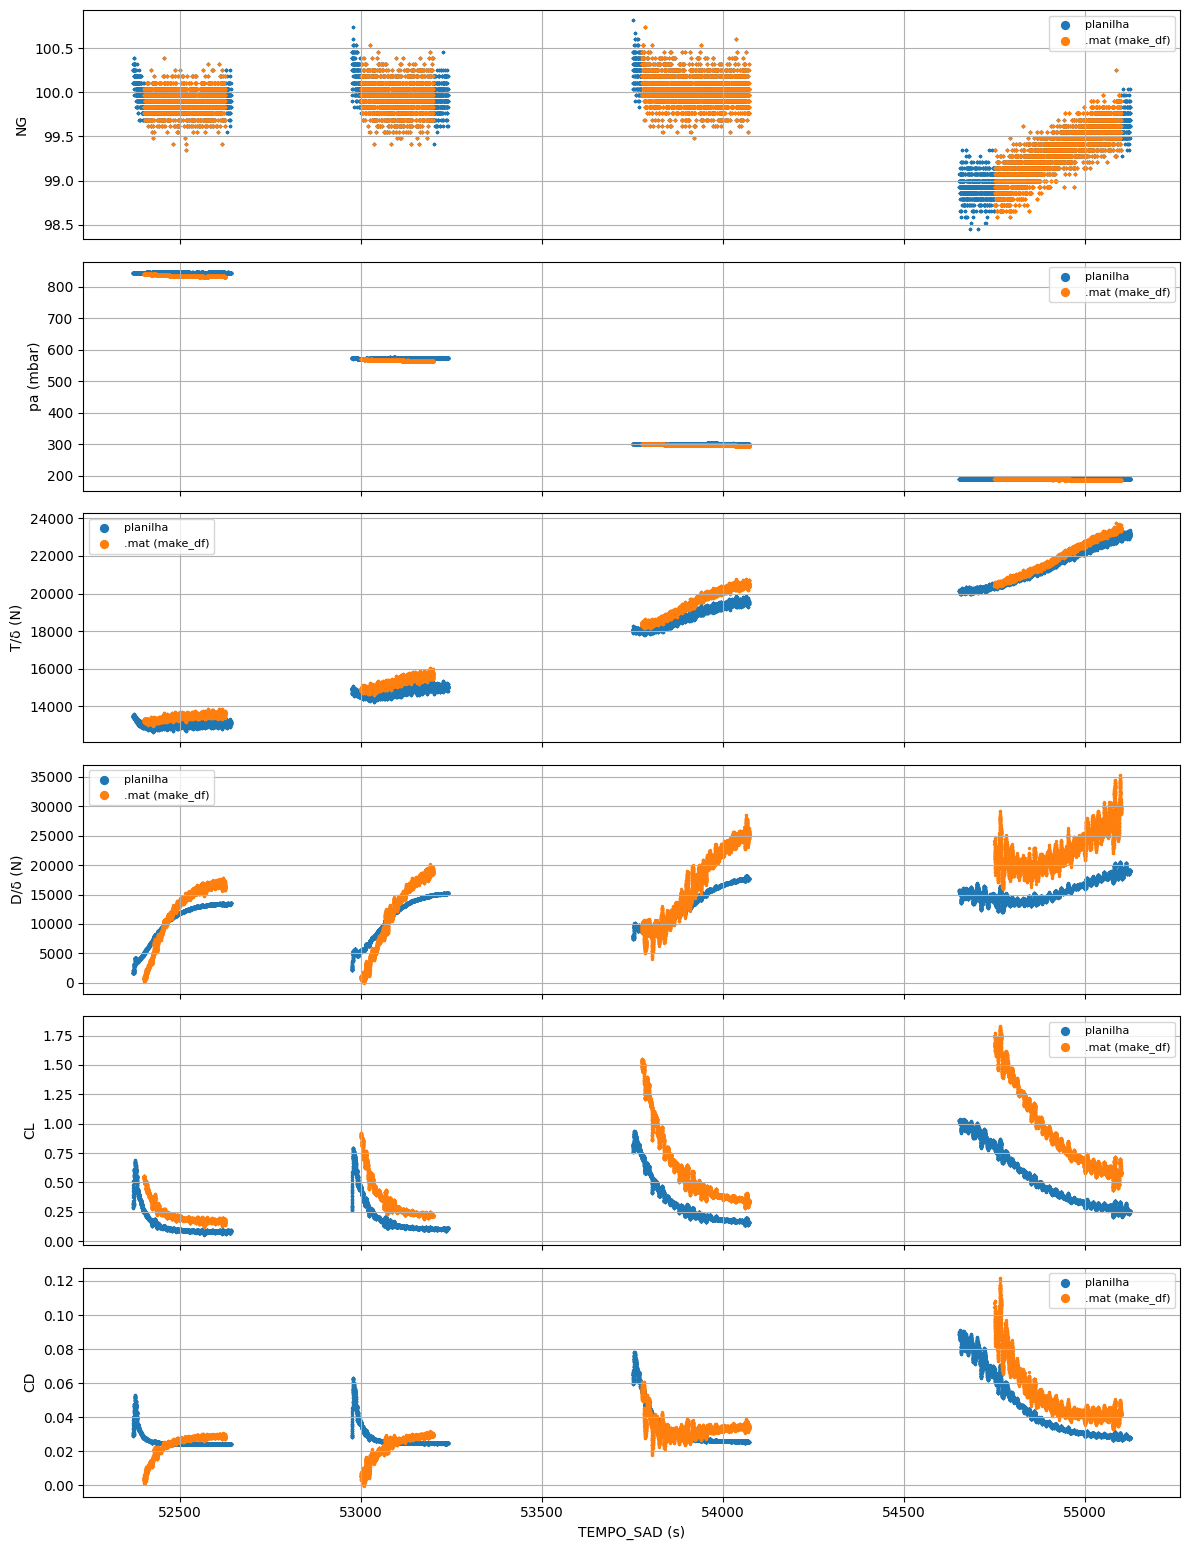

           planilha (mediana)  .mat (mediana)
NG                    99.8303         99.8303
pa (mbar)            302.3536        298.8166
T/δ (N)            18574.1918      19186.9713
D/δ (N)            13803.2110      17396.2394
CL                     0.2682          0.4688
CD                     0.0285          0.0322


In [14]:
# Verificação opcional (precisa das planilhas de aceleração nivelada): compara as grandezas montadas
# a partir do .mat com as da planilha, que eram as usadas na versão anterior deste notebook.
files_excel = ['050', '150', '300', '400']

def make_df_excel():
    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'
    colunas = ['TEMPO_SAD', 'NG', 'W', 'Zp', 'Mach', 'Va', 'Ta_C', 'CL', 'CD', 'Ta_K', 'T', 'No. OBS.']
    all_dfs = [pd.read_excel(local + file + '.xls', skiprows=1, names=colunas) for file in files_excel]
    for i, item in enumerate(all_dfs):
        item['H'] = float(files_excel[i])
    df = pd.concat(all_dfs, ignore_index=True)

    df['Z'] = 0.3048 * df['Zp']
    df['a1'] = df['Z'] <= 11000
    df['a2'] = df['Z'] > 11000
    df['Pa'] = (1013.25 * (1 - 6.87559e-6 * df['Zp']) ** (5.25611)) * (df['a1']) + (226.306 * np.exp(157.696e-6 * (11000 - df['Z']))) * (df['a2'])
    df['Rho'] = df['Pa'] / (2.869 * (df['Ta_K']))
    df['delta'] = df['Pa'] / 1013.25
    df['T_over_delta'] = (df['T'] * 4.44822) / df['delta']                     # N
    df['D'] = df['Rho'] * (df['Va'] * 0.5144) ** 2 * S_ASA * df['CD'] / 2         # N
    df['D_over_delta'] = df['D'] / df['delta']                                 # N
    return df


df_excel = make_df_excel()
df_mat = obter_df_base('')

comparacoes = [   # (rótulo, coluna na planilha, série calculada a partir do .mat)
    ('NG', df_excel['NG'], df_mat['NG']),
    ('pa (mbar)', df_excel['Pa'], df_mat['pa']),
    ('T/δ (N)', df_excel['T_over_delta'], df_mat['T'] * 4.44822 / df_mat['delta']),
    ('D/δ (N)', df_excel['D_over_delta'], df_mat['D_dlt'] * G0),
    ('CL', df_excel['CL'], df_mat['CL']),
    ('CD', df_excel['CD'], df_mat['CD']),
]
fig, axs = plt.subplots(len(comparacoes), 1, figsize=(12, 2.6 * len(comparacoes)), sharex=True)
for ax, (rotulo, s_excel, s_mat) in zip(axs, comparacoes):
    ax.scatter(df_excel['TEMPO_SAD'], s_excel, s=2, label='planilha')
    ax.scatter(df_mat['TEMPO_SAD'], s_mat, s=2, label='.mat (make_df)')
    ax.set_ylabel(rotulo); ax.grid(True); ax.legend(markerscale=4, fontsize=8)
axs[-1].set_xlabel('TEMPO_SAD (s)')
fig.tight_layout()
plt.show()

print(pd.DataFrame({r: {'planilha (mediana)': np.nanmedian(a), '.mat (mediana)': np.nanmedian(b)}
                    for r, a, b in comparacoes}).T.round(4))

### Pipeline

In [15]:
def scale_data(df, features, targets):
    """Um MinMaxScaler por coluna, ajustado só no treino e aplicado à coluna inteira.
    Devolve {coluna: scaler}, de modo que cada target é desnormalizado com o SEU scaler.
    (Na versão anterior, scaler_y era reajustado a cada target e ficava só com o último;
    com dois targets, o inverse_transform aplicava a escala de T também a CD ou D/delta.)"""
    scalers = {}
    treino = df['type'] == 'train'
    for col in dict.fromkeys(features + targets):      # sem repetição (ex.: Mach nas duas sub-redes)
        scaler = MinMaxScaler()
        scaler.fit(df.loc[treino, [col]])
        df[col + '_scaled'] = scaler.transform(df[[col]]).ravel().astype(np.float32)
        scalers[col] = scaler
    return df, scalers

In [16]:
def _hp_ramo(architecture, chave, nome, padrao):
    """Valor específico da sub-rede (ex.: 'neurons_T') ou, na falta dele, o genérico ('neurons')."""
    return architecture.get(f'{chave}_{nome}', architecture.get(chave, padrao))


def build_model(ramos, architecture={}, hyperparameters={}):
    """Uma sub-rede independente por ramo (sem pesos compartilhados).
    ramos: lista de {'nome', 'features', 'targets'}.
      - arquitetura combinada (Fig. 3.2/3.3): um ramo com dois targets;
      - arquitetura separada  (Fig. 3.4/3.5): ramo 'D' e ramo 'T', cada um com seu target.
    Tamanho de cada sub-rede: 'neurons_<nome>' / 'camadas_ocultas_<nome>' (ex.: 'neurons_T'),
    com 'neurons' / 'camadas_ocultas' como valor genérico."""
    activation   = architecture.get('activation', 'relu')
    dropout_rate = architecture.get('dropout', 0.0)

    entradas, saidas = [], []
    for ramo in ramos:
        nome = ramo['nome']
        neurons  = int(_hp_ramo(architecture, 'neurons', nome, 32))
        n_hidden = int(_hp_ramo(architecture, 'camadas_ocultas', nome, 2))

        x_in = layers.Input(shape=(len(ramo['features']),), name=f'Entrada_{nome}')
        x = x_in
        for i in range(n_hidden):
            x = layers.Dense(neurons, activation=activation, name=f'NN_{nome}_hidden_{i+1}')(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'NN_{nome}_dropout_{i+1}')(x)
        y_out = layers.Dense(len(ramo['targets']), name=f'NN_{nome}_output')(x)

        entradas.append(x_in)
        saidas.append(y_out)

    um_ramo = len(ramos) == 1
    model = Model(
        inputs=entradas[0] if um_ramo else entradas,
        outputs=saidas[0] if um_ramo else saidas,
        name='Rede_' + '_'.join(r['nome'] for r in ramos),
    )

    optimizer = keras.optimizers.get({
        'class_name': hyperparameters.get('optimizer', 'adam'),
        'config': {'learning_rate': hyperparameters.get('learning_rate', 1e-3)},
    })
    loss = hyperparameters.get('loss', 'mse')
    model.compile(optimizer=optimizer, loss=loss if um_ramo else [loss] * len(ramos))
    return model


class EarlyStoppingPorRamo(keras.callbacks.Callback):
    """EarlyStopping com restore_best_weights independente para cada sub-rede.
    Cada ramo tem a sua perda de validação (espaço escalonado), a sua paciência e a sua melhor
    época; um ramo que esgota a paciência fica 'congelado' no seu melhor ponto, o treino só para
    quando todos esgotaram, e no fim cada ramo recebe de volta os pesos da sua melhor época.
    Como as sub-redes não compartilham pesos (e o Adam atua parâmetro a parâmetro), o resultado
    de cada ramo equivale ao de treiná-lo sozinho com EarlyStopping(restore_best_weights=True)."""

    def __init__(self, X_val, Y_val, nomes_ramos, patience, loss='mse', min_delta=0.0):
        super().__init__()
        self.X_val, self.Y_val = X_val, Y_val          # listas: uma entrada/saída por ramo
        self.nomes = list(nomes_ramos)
        self.patience, self.min_delta = patience, min_delta
        self.usa_mae = str(loss).lower() in ('mae', 'mean_absolute_error')

    def _camadas(self, nome):
        return [l for l in self.model.layers if l.name.startswith(f'NN_{nome}_') and l.weights]

    def on_train_begin(self, logs=None):
        n = len(self.nomes)
        self.melhor = [np.inf] * n
        self.espera = [0] * n
        self.melhor_epoca = [0] * n
        self.melhores_pesos = [None] * n
        self.historico = {f'val_loss_{nome}': [] for nome in self.nomes}

    def on_epoch_end(self, epoch, logs=None):
        x = self.X_val[0] if len(self.nomes) == 1 else self.X_val
        pred = self.model(x, training=False)
        pred = pred if isinstance(pred, (list, tuple)) else [pred]
        for i, nome in enumerate(self.nomes):
            erro = keras.ops.convert_to_numpy(pred[i]) - self.Y_val[i]
            perda = float(np.mean(np.abs(erro)) if self.usa_mae else np.mean(erro ** 2))
            self.historico[f'val_loss_{nome}'].append(perda)
            if self.espera[i] >= self.patience:
                continue                                  # ramo já parado: não atualiza mais
            if perda < self.melhor[i] - self.min_delta:
                self.melhor[i], self.espera[i], self.melhor_epoca[i] = perda, 0, epoch
                self.melhores_pesos[i] = [l.get_weights() for l in self._camadas(nome)]
            else:
                self.espera[i] += 1
        if all(e >= self.patience for e in self.espera):
            self.model.stop_training = True

    def on_train_end(self, logs=None):
        for i, nome in enumerate(self.nomes):
            if self.melhores_pesos[i] is not None:
                for l, w in zip(self._camadas(nome), self.melhores_pesos[i]):
                    l.set_weights(w)

In [17]:
def _arrays_ramos(df, ramos, mask, chave):
    """Uma matriz por ramo com as colunas escalonadas de 'features' ou 'targets'."""
    return [df.loc[mask, [c + '_scaled' for c in r[chave]]].to_numpy(dtype=np.float32) for r in ramos]


def train_model(df, ramos, model, hyperparameters):
    treino, val = df['type'] == 'train', df['type'] == 'val'
    X_train, X_val = _arrays_ramos(df, ramos, treino, 'features'), _arrays_ramos(df, ramos, val, 'features')
    Y_train, Y_val = _arrays_ramos(df, ramos, treino, 'targets'), _arrays_ramos(df, ramos, val, 'targets')

    um_ramo = len(ramos) == 1
    _s = (lambda lista: lista[0]) if um_ramo else (lambda lista: lista)

    parada = EarlyStoppingPorRamo(
        X_val, Y_val, [r['nome'] for r in ramos],
        patience=hyperparameters['patience'],
        loss=hyperparameters.get('loss', 'mse'),
    )

    training_history = model.fit(
        _s(X_train), _s(Y_train),
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        validation_data=(_s(X_val), _s(Y_val)),
        callbacks=[parada],
        verbose=0,
    )
    # curvas de validação de cada sub-rede (as do Keras são a soma dos ramos)
    training_history.history.update(parada.historico)
    melhores_epocas = dict(zip(parada.nomes, parada.melhor_epoca))
    return model, training_history, melhores_epocas


def pipeline(tipo_dados, ramos, architecture, hyperparameters, seed=0):
    keras.backend.clear_session()      # antes do set_seed: clear_session zera o estado global do Keras
    set_seed(seed)
    df = preparar_df(tipo_dados, ramos)
    features = [f for r in ramos for f in r['features']]
    targets  = [t for r in ramos for t in r['targets']]
    df, scalers = scale_data(df, features, targets)
    model = build_model(ramos, architecture, hyperparameters)
    model, training_history, melhores_epocas = train_model(df, ramos, model, hyperparameters)
    return df, scalers, model, training_history, melhores_epocas

In [18]:
# Janelas de TEMPO_SAD avaliadas em cada voo (as mesmas do scriptPMG_refactored_pinn).
# Valem para métricas e figuras, não para o treino. Voo fora do dicionário: avaliado inteiro.
# {} = sem recorte.
JANELAS_AVALIACAO = {
    '039_2013_VIN_FND': (5e4, 7e4),
    '040_2013_ASO_VTO': (0, 5e4),
    '041_2013_GEO_AIR': (0, 1e5),
    '042_2013_VAU_FTR': (0, 8e4),
}


def recortar_janelas(sub):
    """Mantém só os pontos dentro da janela de avaliação do respectivo voo."""
    manter = pd.Series(True, index=sub.index)
    for filename, (t0, t1) in JANELAS_AVALIACAO.items():
        do_voo = sub['filename'] == filename
        manter &= ~do_voo | ((sub['TEMPO_SAD'] > t0) & (sub['TEMPO_SAD'] < t1))
    return sub[manter]


def prever(model, df, ramos, scalers):
    """Previsão em todo o df; cada target é desnormalizado com o seu próprio scaler."""
    X = [df[[f + '_scaled' for f in r['features']]].to_numpy(dtype=np.float32) for r in ramos]
    pred = model.predict(X[0] if len(ramos) == 1 else X, verbose=0)
    pred = pred if isinstance(pred, (list, tuple)) else [pred]
    for r, p in zip(ramos, pred):
        p = np.asarray(p).reshape(len(df), len(r['targets']))
        for j, t in enumerate(r['targets']):
            df[t + '_pred'] = scalers[t].inverse_transform(p[:, [j]]).ravel()
    return df


def calcular_metricas(df, ramos, scalers, conjuntos=('val', 'test')):
    """Uma linha por (conjunto, target), dentro das janelas de avaliação.
    nmae = MAE / (faixa do target no treino) · 100 [%]: adimensional, comparável entre targets e
           robusto perto de zero -> é o score padrão da análise;
    mape = média de |erro relativo| [%] (pontos com real = 0 ignorados; instável se o target passa
           perto de zero, como D/δ e T no voo completo);
    mpe  = média do erro relativo COM sinal (a métrica 'avg_error' da versão anterior)."""
    linhas = []
    for conjunto in conjuntos:
        sub = recortar_janelas(df[df['type'] == conjunto])
        for r in ramos:
            for t in r['targets']:
                real = sub[t].to_numpy(dtype=float)
                erro = sub[t + '_pred'].to_numpy(dtype=float) - real
                with np.errstate(divide='ignore', invalid='ignore'):
                    rel = np.where(real != 0, 100 * erro / real, np.nan)
                linhas.append({
                    'conjunto': conjunto, 'ramo': r['nome'], 'target': t, 'n_pontos': len(sub),
                    'mae': np.mean(np.abs(erro)), 'rmse': np.sqrt(np.mean(erro ** 2)),
                    'nmae': 100 * np.mean(np.abs(erro)) / float(scalers[t].data_range_[0]),
                    'mape': np.nanmean(np.abs(rel)), 'mpe': np.nanmean(rel),
                })
    return linhas


def figura_resultados(df, ramos, historico, metricas, titulo='', conjuntos=('val', 'test'), dot_size=2):
    """Linha 0: curvas de perda. Depois, para cada target: real vs. previsto e erro absoluto,
    uma coluna por conjunto (dentro das janelas de avaliação)."""
    alvos = [t for r in ramos for t in r['targets']]
    n_lin = 1 + 2 * len(alvos)
    fig = plt.figure(figsize=(7 * len(conjuntos), 3.2 * n_lin))
    gs = fig.add_gridspec(n_lin, len(conjuntos))

    ax = fig.add_subplot(gs[0, :])
    ax.plot(historico['loss'], label='Treino (soma dos ramos)')
    ax.plot(historico['val_loss'], label='Validação (soma dos ramos)')
    curvas_ramos = [k for k in historico if k.startswith('val_loss_')]
    if len(curvas_ramos) > 1:
        for k in curvas_ramos:
            ax.plot(historico[k], '--', label=f'Validação ({k[len("val_loss_"):]})')
    ax.set_yscale('log'); ax.set_xlabel('Época'); ax.set_ylabel('Perda (escalonada)')
    ax.legend(fontsize=8); ax.grid(True)

    met = pd.DataFrame(metricas).set_index(['conjunto', 'target'])
    for k, t in enumerate(alvos):
        for j, conjunto in enumerate(conjuntos):
            sub = recortar_janelas(df[df['type'] == conjunto])
            m = met.loc[(conjunto, t)]
            a1 = fig.add_subplot(gs[1 + 2 * k, j])
            a2 = fig.add_subplot(gs[2 + 2 * k, j], sharex=a1)
            a1.scatter(sub['TEMPO_SAD'], sub[t], s=dot_size, label=f'{t} real')
            a1.scatter(sub['TEMPO_SAD'], sub[t + '_pred'], s=dot_size, label=f'{t} previsto')
            a1.set_title(f'{t} — {conjunto}'); a1.legend(markerscale=4, fontsize=8); a1.grid(True)
            a2.scatter(sub['TEMPO_SAD'], (sub[t + '_pred'] - sub[t]).abs(), s=dot_size)
            a2.set_title(f'nMAE = {m["nmae"]:.2f}% | MAE = {m["mae"]:.3g} | '
                         f'MAPE = {m["mape"]:.2f}% | MPE = {m["mpe"]:+.2f}%', fontsize=10)
            a2.set_ylabel(f'|erro| ({t})'); a2.set_xlabel('TEMPO_SAD (s)'); a2.grid(True)

    fig.suptitle(titulo, fontsize=12)
    fig.tight_layout()
    return fig

In [19]:
ARQ_PADRAO = {'neurons': 60, 'camadas_ocultas': 2, 'activation': 'relu', 'dropout': 0.0}
HP_PADRAO  = {'optimizer': 'adam', 'learning_rate': 1e-4, 'epochs': 60, 'batch_size': 32,
              'patience': 3, 'loss': 'mse'}


def analyze(tipo_dados, abordagem, architecture=None, hyperparameters=None, seed=0, plot=False,
            conjuntos_plot=('val', 'test')):
    """tipo_dados: 'completo' (voos 039–042 inteiros) ou '' (trechos de aceleração nivelada do voo 039).
    architecture/hyperparameters completam (não substituem) ARQ_PADRAO/HP_PADRAO.
    Ex.: architecture={'neurons_T': 40, 'camadas_ocultas_T': 2, 'neurons_D': 10, 'camadas_ocultas_D': 1}"""
    architecture = {**ARQ_PADRAO, **(architecture or {})}
    hyperparameters = {**HP_PADRAO, **(hyperparameters or {})}
    ramos = abordagem['ramos']

    df, scalers, model, training_history, melhores_epocas = pipeline(tipo_dados, ramos, architecture, hyperparameters, seed)
    df = prever(model, df, ramos, scalers)

    metricas = calcular_metricas(df, ramos, scalers)
    for linha in metricas:
        linha['melhor_epoca'] = melhores_epocas[linha['ramo']]
        linha['epocas_treinadas'] = len(training_history.history['loss'])

    if plot:
        figura_resultados(df, ramos, training_history.history, metricas,
                          titulo=f"{abordagem['nome']} | dados: {tipo_dados or 'aceleração nivelada'}", conjuntos=conjuntos_plot)
        plt.show()

    return df, scalers, model, training_history, metricas

### Abordagens (Fig. 3.2 a 3.5 do TG) e escolha dos dados

In [20]:
# Fonte dos dados de TODO o notebook: '' = trechos A–D de aceleração nivelada do voo 039;
# 'completo' = voos 039 (A), 040 (B), 041 (C) e 042 (D) inteiros. Em ambos, B é validação/teste.
TIPO_DADOS = ''

# Targets corrigidos: Tn_dlt = T·cos(α)/δ e D_dlt = Tn_dlt − (Ḣ/V)(W/δ), em kgf — as grandezas que
# Z1 e Z2 representam no scriptPMG_refactored_pinn. Sem correção: T (lbf, do thrust deck) e CD.
ABORDAGENS = {
    'combinada': {
        'nome': 'Fig. 3.2 — combinada, sem correções',
        'ramos': [{'nome': 'DT', 'features': ['CL', 'Mach', 'NG', 'W', 'Zp', 'Ta_K'], 'targets': ['CD', 'T']}],
    },
    'combinada_corrigida': {
        'nome': 'Fig. 3.3 — combinada, com correções θ e δ',
        'ramos': [{'nome': 'DT', 'features': ['CL', 'Mach', 'N1_over_sqrt_theta'],
                   'targets': ['D_dlt', 'Tn_dlt']}],
    },
    'separada': {
        'nome': 'Fig. 3.4 — separada, sem correções',
        'ramos': [{'nome': 'D', 'features': ['CL', 'Mach'], 'targets': ['CD']},
                  {'nome': 'T', 'features': ['Mach', 'NG', 'W', 'Zp', 'Ta_K'], 'targets': ['T']}],
    },
    'separada_corrigida': {
        'nome': 'Fig. 3.5 — separada, com correções θ e δ',
        'ramos': [{'nome': 'D', 'features': ['CL', 'Mach'], 'targets': ['D_dlt']},
                  {'nome': 'T', 'features': ['Mach', 'N1_over_sqrt_theta'], 'targets': ['Tn_dlt']}],
    },
}

### Rodadas iniciais (arquitetura padrão)

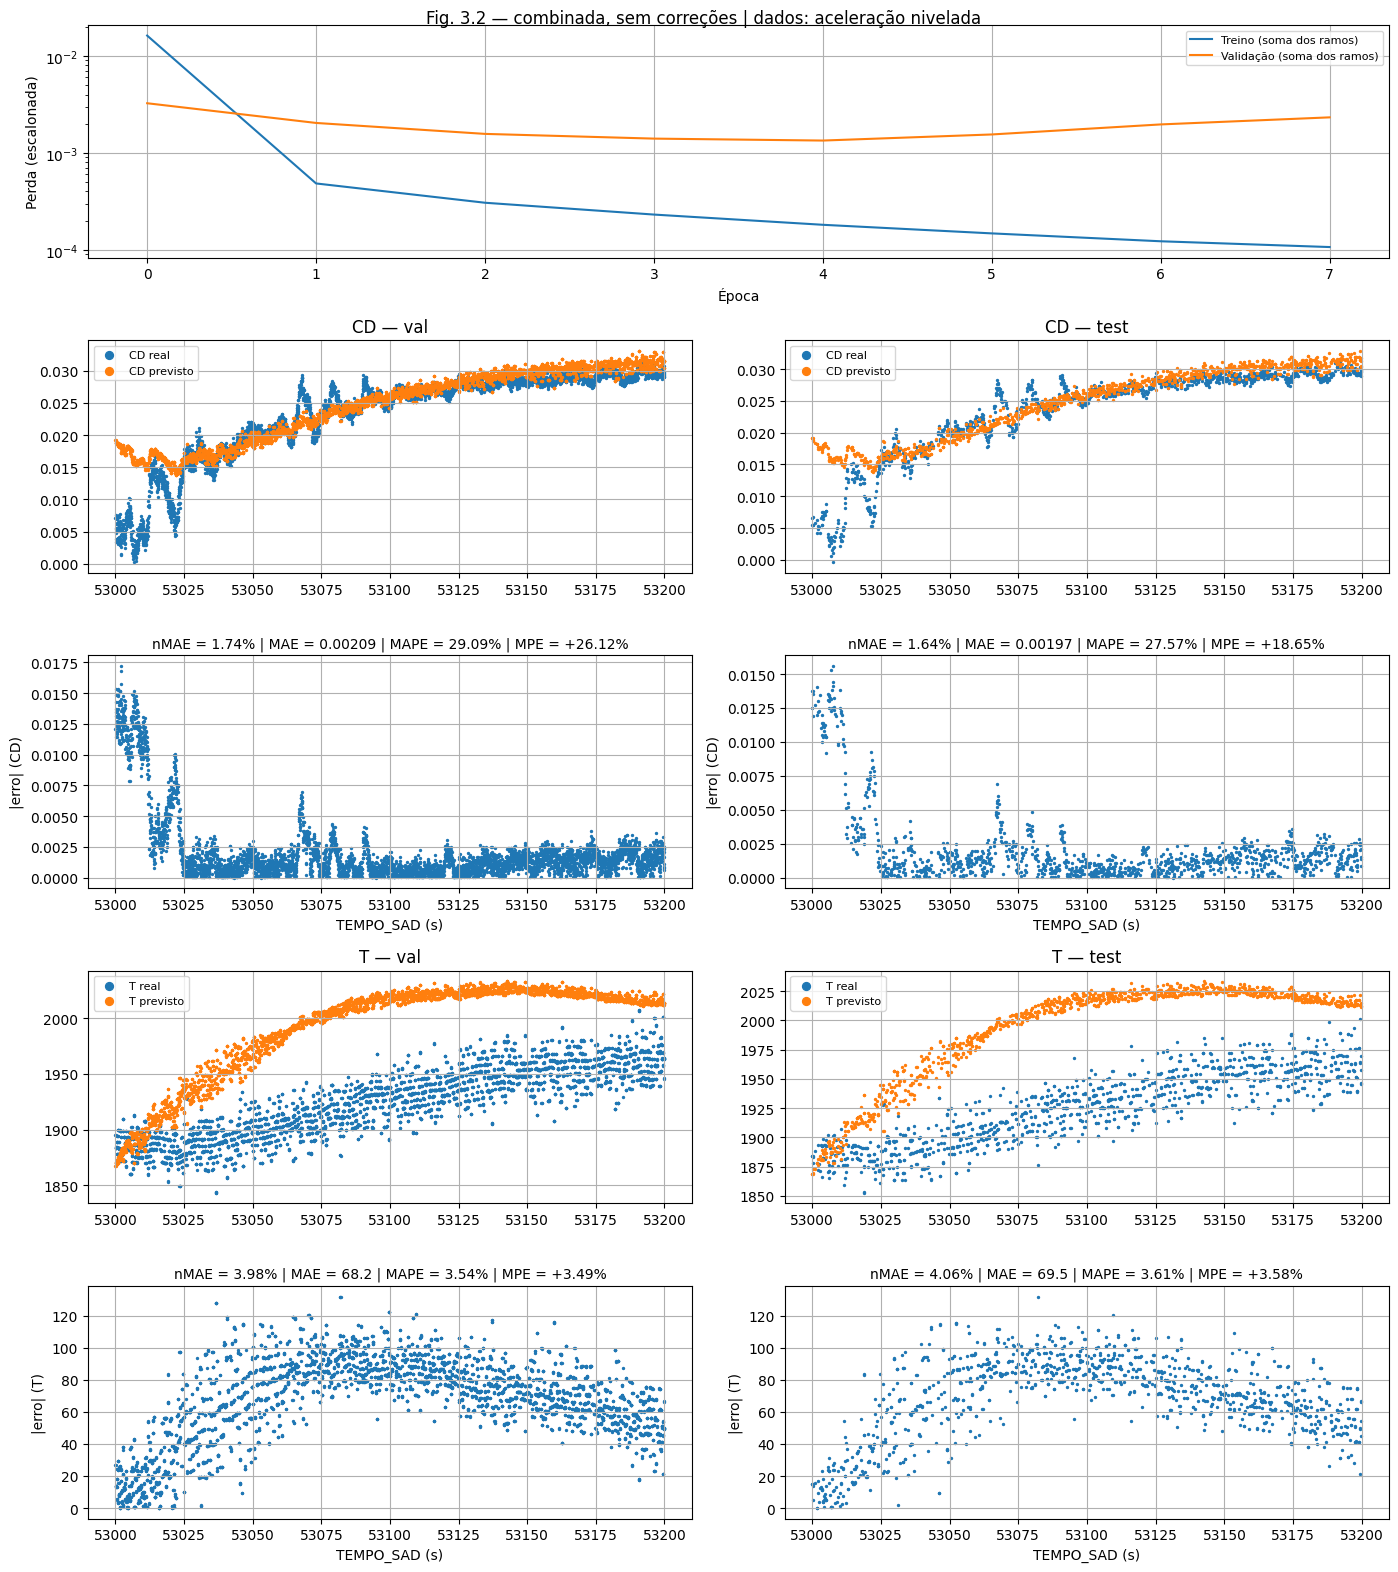

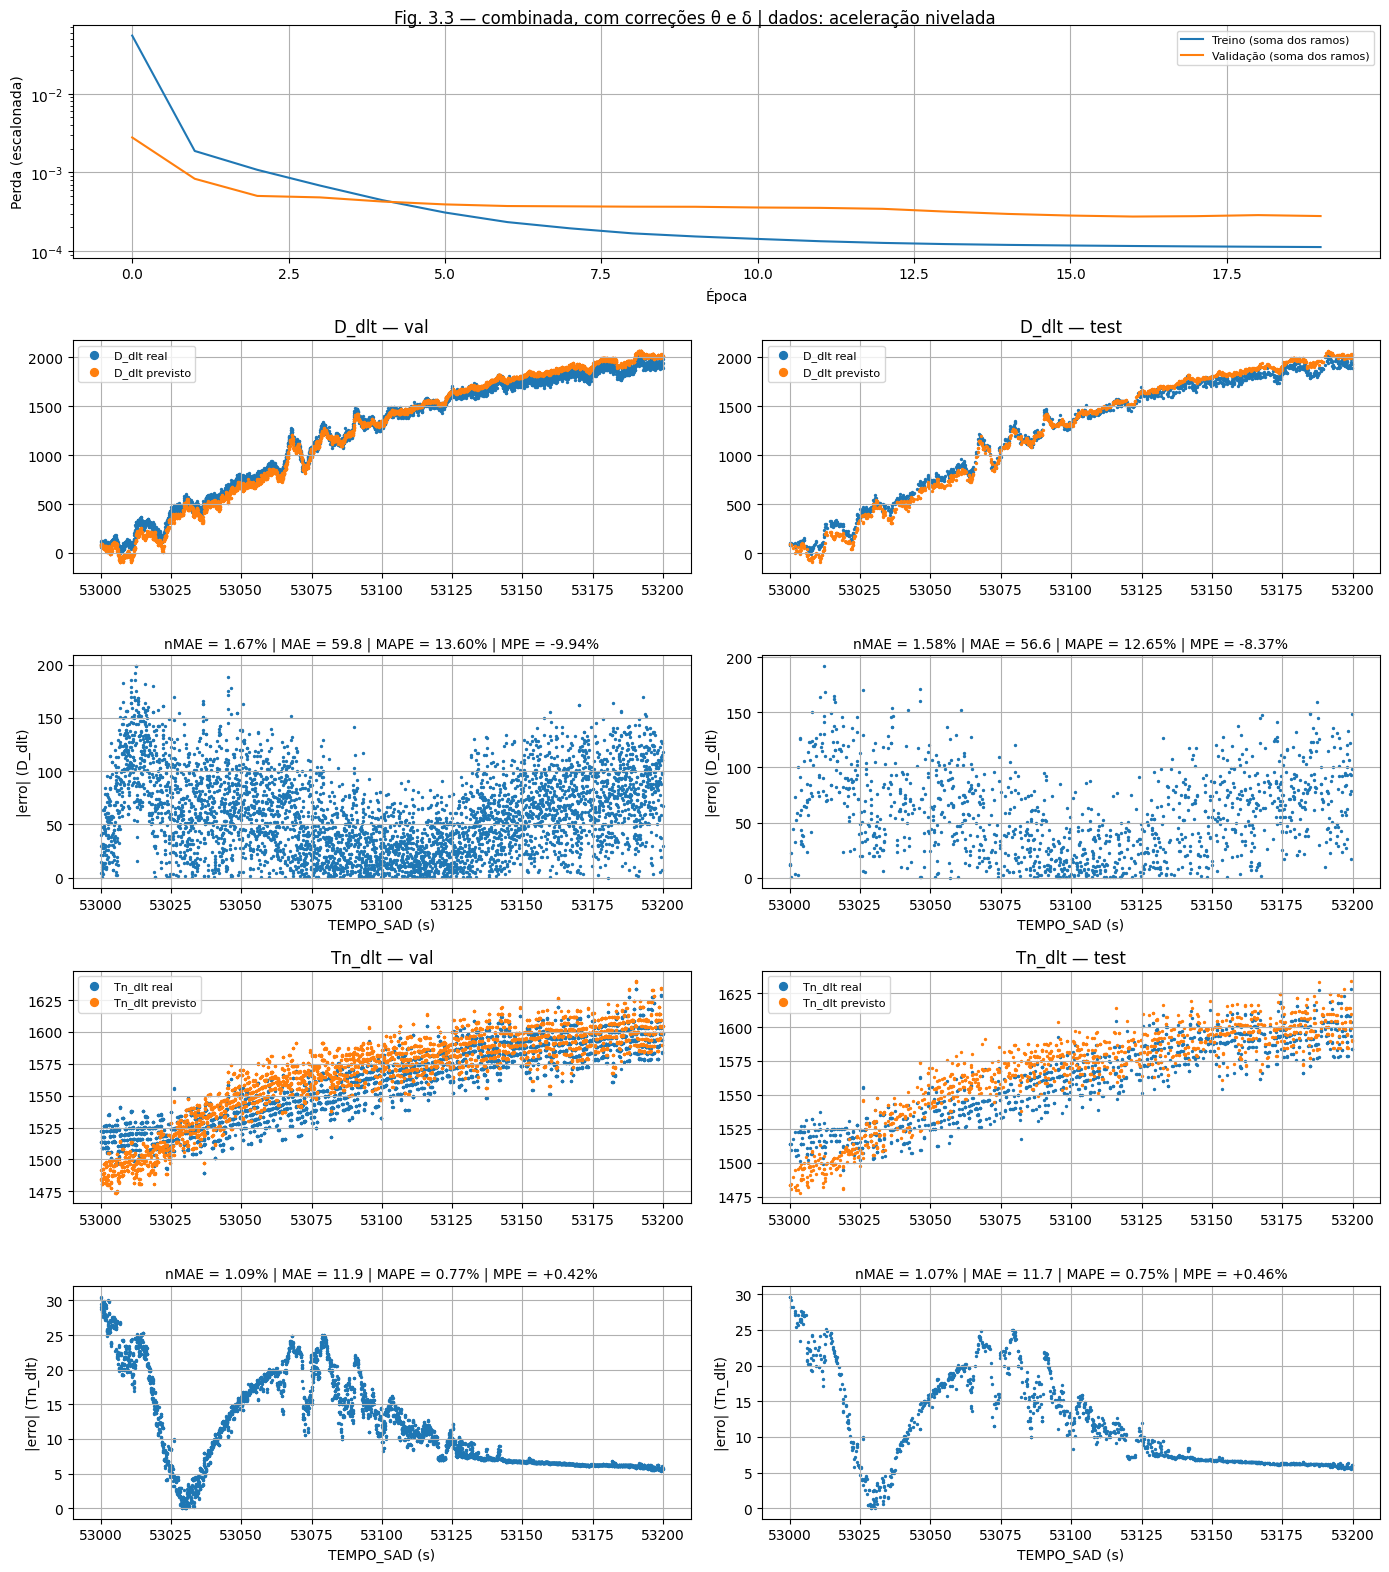

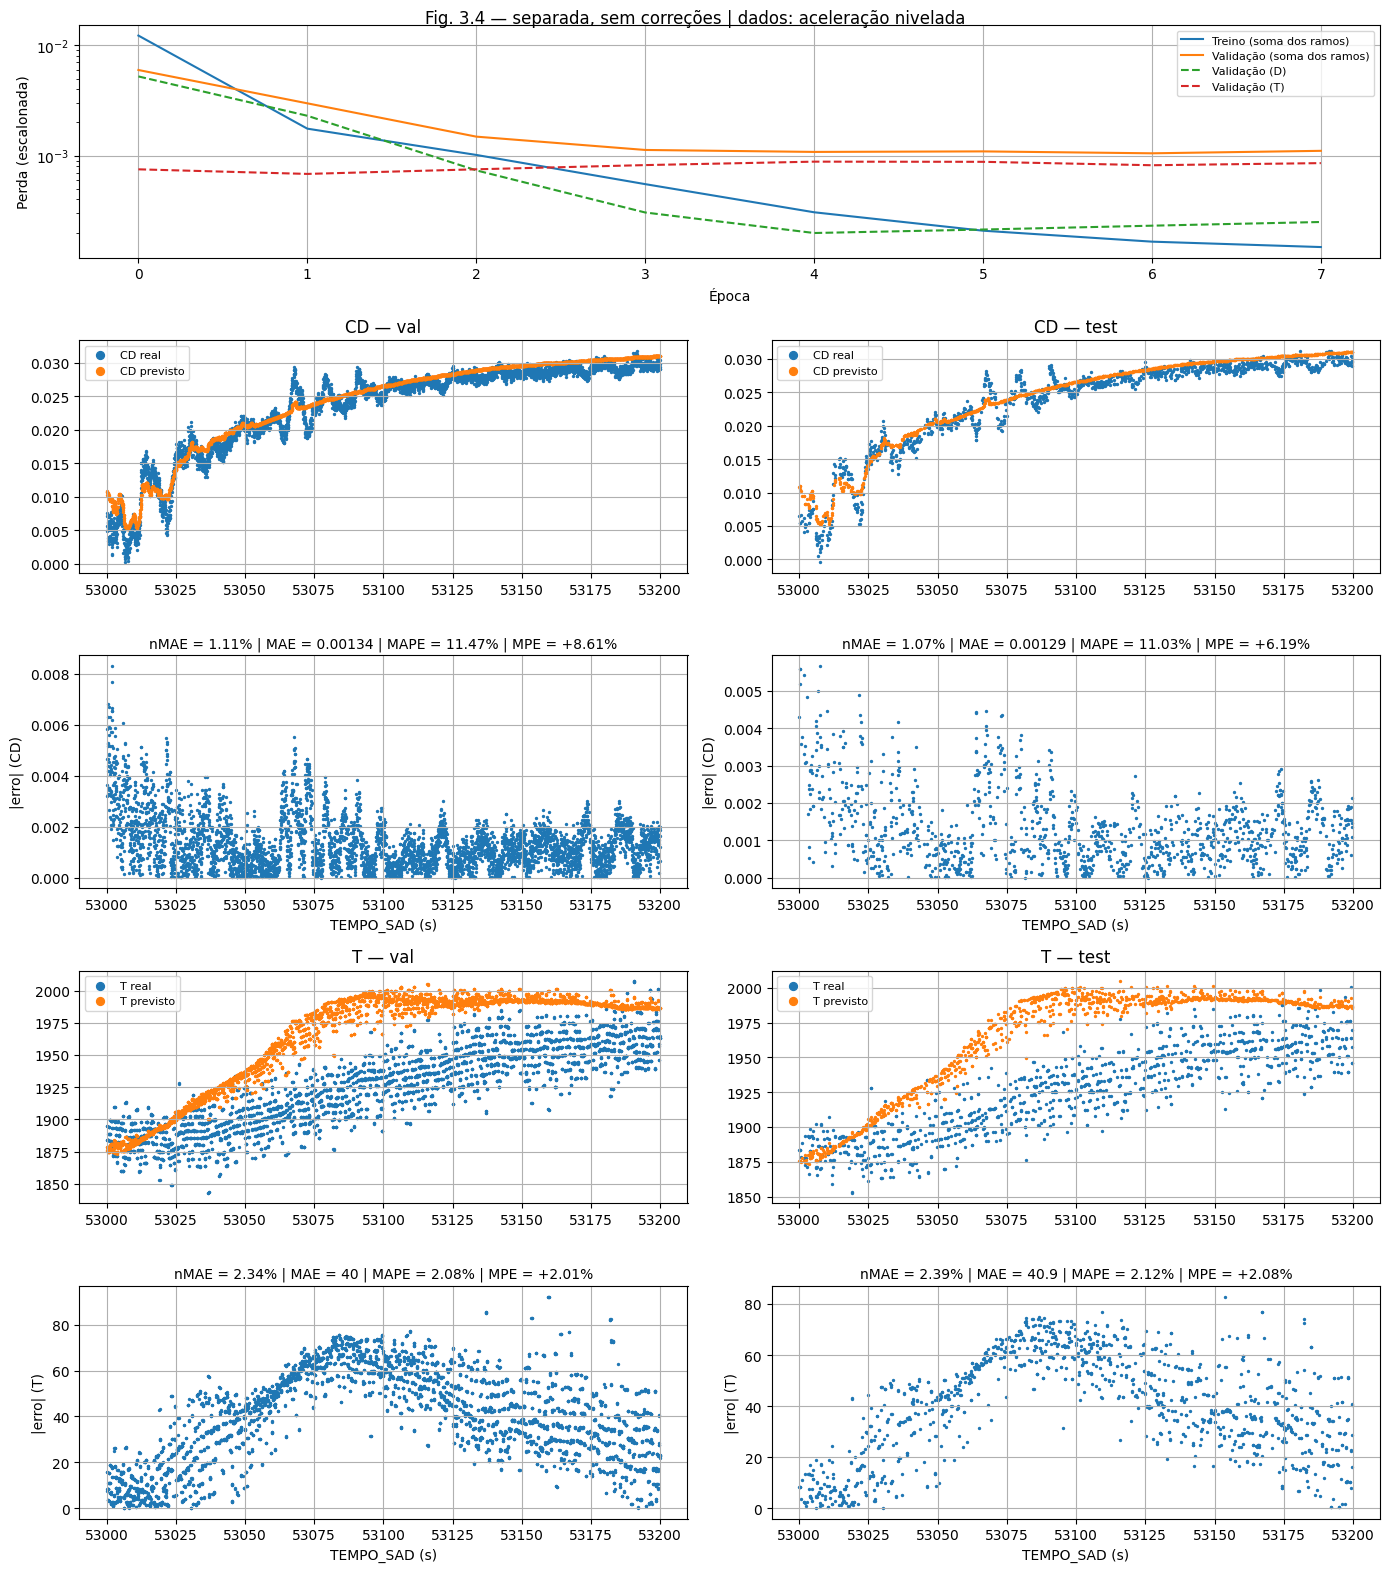

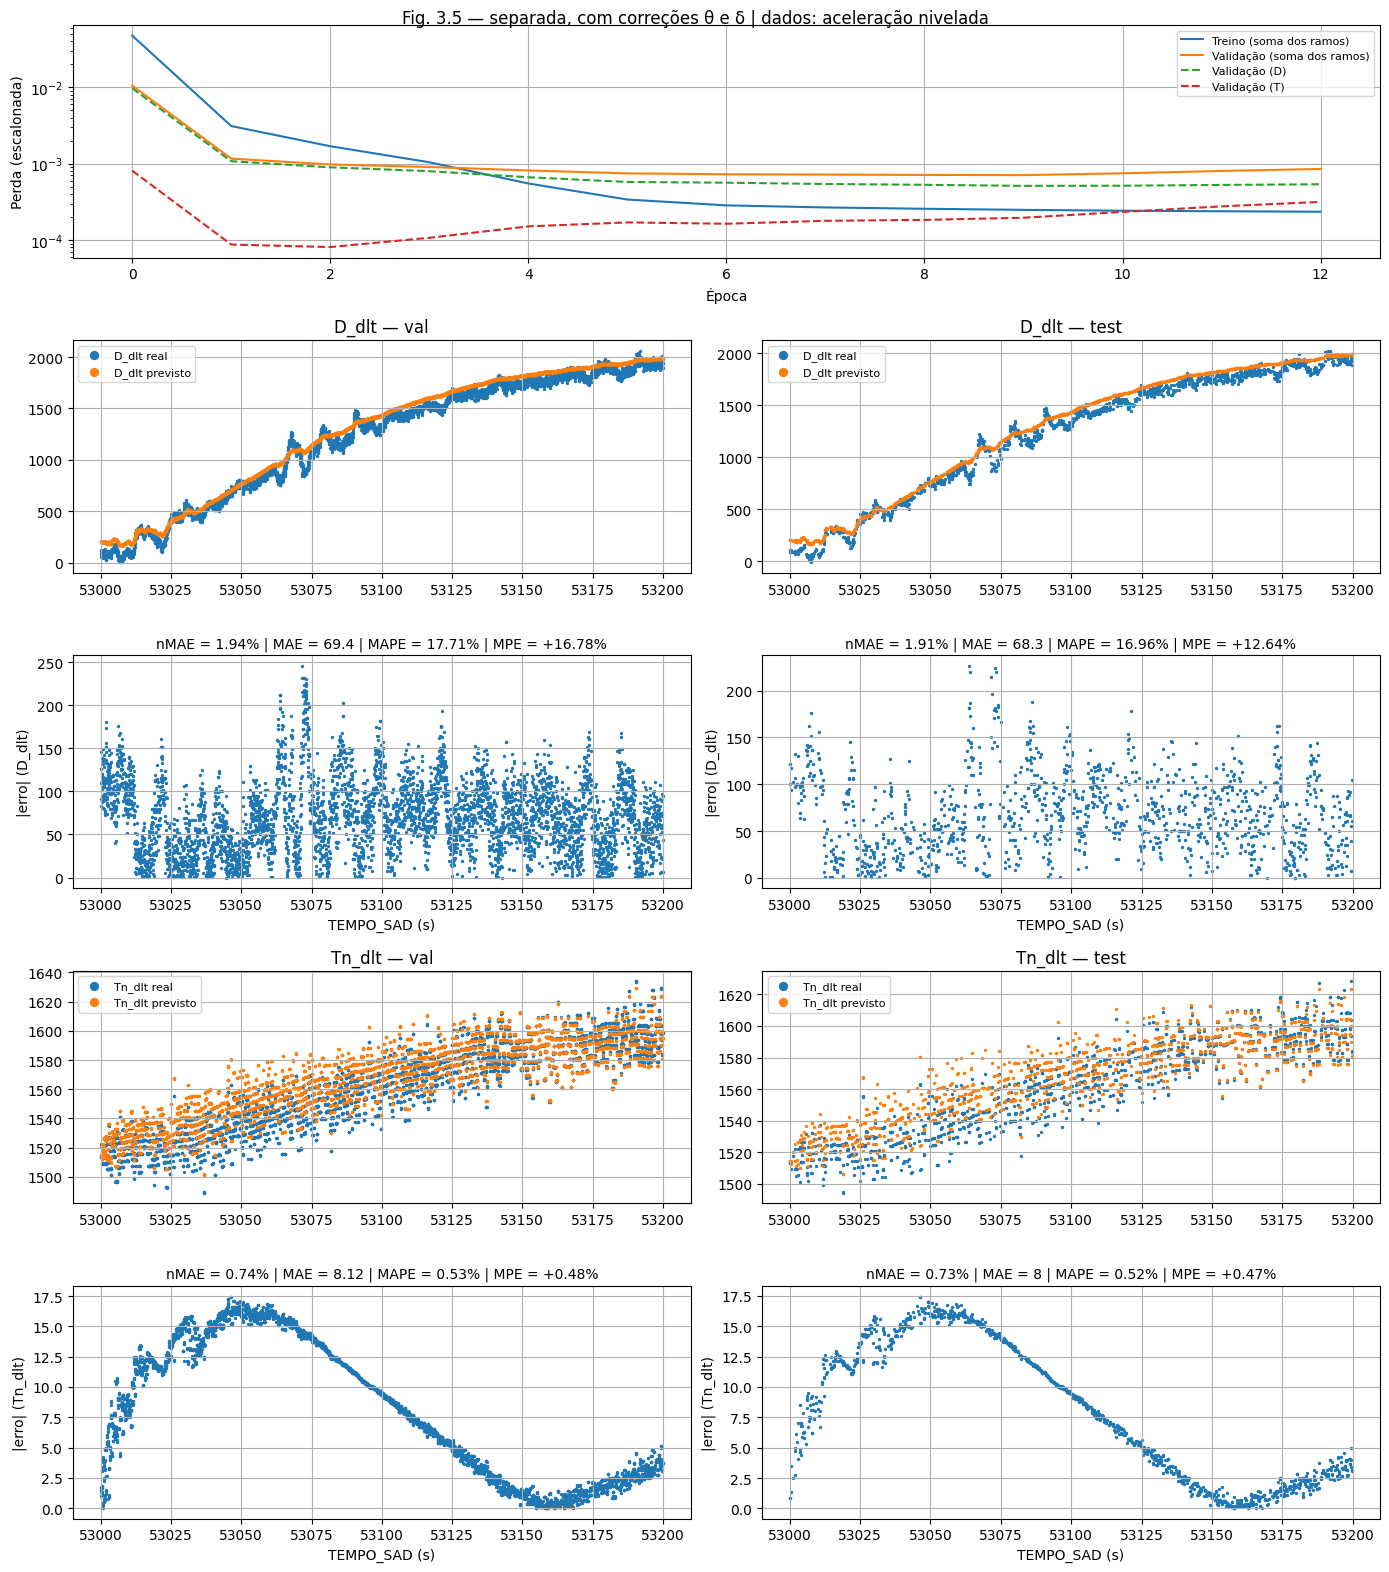

In [21]:
resultados_iniciais = {}
for chave, abordagem in ABORDAGENS.items():
    resultados_iniciais[chave] = analyze(TIPO_DADOS, abordagem, plot=True)

### Busca de hiperparâmetros por LHS

In [22]:
ARQ_MODELO    = 'model.keras'
ARQ_HISTORICO = 'history.pkl'
ARQ_SCALERS   = 'scalers.pkl'
ARQ_METRICAS  = 'metricas.csv'
ARQ_CONFIG    = 'config.json'
ARQ_PAGINA    = 'pagina_pdf.png'
ARQ_CONCLUIDO = 'CONCLUIDO.json'   # escrito por ÚLTIMO: só existe se todo o resto foi salvo

_styles_ckpt = getSampleStyleSheet()


def checkpoint_completo(combo_dir):
    """True só se a combinação terminou de ser treinada E salva."""
    necessarios = [ARQ_CONCLUIDO, ARQ_MODELO, ARQ_METRICAS, ARQ_PAGINA]
    return all(os.path.isfile(os.path.join(combo_dir, a)) for a in necessarios)


def salvar_checkpoint(combo_dir, model, training_history, scalers, metricas_combo, config):
    """Salva tudo sobre a rede recém-treinada. O marcador CONCLUIDO vem por último."""
    os.makedirs(combo_dir, exist_ok=True)

    model.save(os.path.join(combo_dir, ARQ_MODELO))

    hist = training_history.history if hasattr(training_history, 'history') else training_history
    joblib.dump(hist, os.path.join(combo_dir, ARQ_HISTORICO))

    joblib.dump(scalers, os.path.join(combo_dir, ARQ_SCALERS))

    pd.DataFrame(metricas_combo).to_csv(os.path.join(combo_dir, ARQ_METRICAS), index=False)

    with open(os.path.join(combo_dir, ARQ_CONFIG), 'w', encoding='utf-8') as f:
        json.dump(config, f, indent=2, ensure_ascii=False)

    with open(os.path.join(combo_dir, ARQ_CONCLUIDO), 'w', encoding='utf-8') as f:
        json.dump({
            'concluido_em': pd.Timestamp.now().isoformat(),
            'epocas_treinadas': len(hist['loss']),
        }, f, indent=2)


def carregar_checkpoint(combo_dir):
    """Recarrega uma rede salva (para análises posteriores, fora da busca)."""
    model   = keras.models.load_model(os.path.join(combo_dir, ARQ_MODELO), compile=False)
    hist    = joblib.load(os.path.join(combo_dir, ARQ_HISTORICO))
    scalers = joblib.load(os.path.join(combo_dir, ARQ_SCALERS))
    with open(os.path.join(combo_dir, ARQ_CONFIG), encoding='utf-8') as f:
        config = json.load(f)
    metricas_combo = pd.read_csv(os.path.join(combo_dir, ARQ_METRICAS))
    return model, hist, scalers, config, metricas_combo


def adicionar_pagina_pdf(pdf_story, titulo, page_img_path, max_largura_cm=18.0, max_altura_cm=24.0):
    pdf_story.append(Paragraph(titulo, _styles_ckpt['Heading3']))
    img_w_px, img_h_px = PILImage.open(page_img_path).size
    razao = img_w_px / img_h_px
    largura_cm = max_largura_cm
    altura_cm = largura_cm / razao
    if altura_cm > max_altura_cm:
        altura_cm = max_altura_cm
        largura_cm = altura_cm * razao
    pdf_story.append(Image(page_img_path, width=largura_cm * cm, height=altura_cm * cm))
    pdf_story.append(PageBreak())

In [23]:
# Os dados vêm de TIPO_DADOS (célula das abordagens). Cada tipo de dados tem a sua pasta, para que os
# checkpoints de aceleração nivelada e de voo completo nunca se misturem.
ABORDAGENS_LHS = ['combinada', 'combinada_corrigida', 'separada', 'separada_corrigida']

seeds = [0, 1, 2]
# ---------------- Desenho LHS (um por abordagem) ----------------
N_LHS    = 32
LHS_SEED = 0       # ao adicionar um lote novo (LOTE = 'L2'), troque também a LHS_SEED
LOTE     = 'L1'

# Opções por sub-rede: chave = nome do ramo ('D', 'T' ou 'DT'); 'padrao' vale para os não listados.
# D e T são amostrados em dimensões independentes do LHS, então cada um tem o seu tamanho.
CAMADAS_OPTS   = {'padrao': [1, 2, 3, 4]}
NEURONIOS_OPTS = {'padrao': [5, 10, 20, 40, 60, 80]}
# ex.: NEURONIOS_OPTS = {'padrao': [5, 10, 20, 40], 'T': [20, 40, 60, 80, 100]}

LEARNING_RATE   = (1e-4, 1e-2)    # tupla -> amostrado em escala log; número -> valor fixo
BATCH_SIZE_OPTS = [16, 32, 64]    # lista com um único valor -> valor fixo

ARQ_FIXOS = {'activation': 'relu', 'dropout': 0.0}
HP_FIXOS  = {'optimizer': 'adam', 'epochs': 200, 'patience': 20, 'loss': 'mse'}

nome_iteracao = 'lhs_input_parameter_analysis'
folder = os.path.join('Grid_Searches_InputAnalysis', f"{nome_iteracao}_{TIPO_DADOS or 'nivelada'}")

In [24]:
def amostrar_log(faixa, u_col):
    """faixa: número (valor fixo) ou tupla (lo, hi) para amostragem log."""
    if np.isscalar(faixa):
        return np.full(len(u_col), float(faixa))
    lo, hi = np.log10(faixa[0]), np.log10(faixa[1])
    return 10 ** (lo + u_col * (hi - lo))


def amostrar_opcoes(opcoes, u_col):
    opcoes = list(opcoes)
    idx = np.minimum((u_col * len(opcoes)).astype(int), len(opcoes) - 1)
    return [opcoes[i] for i in idx]


def _opcoes(dic, nome_ramo):
    return dic.get(nome_ramo, dic['padrao'])


def gerar_desenho_lhs(n, seed, nomes_ramos):
    d = 2 * len(nomes_ramos) + 2          # (camadas, neurônios) por ramo + learning rate + batch size
    try:
        sampler = qmc.LatinHypercube(d=d, optimization='random-cd', rng=np.random.default_rng(seed))
    except TypeError:  # SciPy < 1.15
        sampler = qmc.LatinHypercube(d=d, optimization='random-cd', seed=seed)
    u = sampler.random(n)
    desenho = {'lhs_id': np.arange(n)}
    for k, nome in enumerate(nomes_ramos):
        desenho[f'camadas_{nome}']   = amostrar_opcoes(_opcoes(CAMADAS_OPTS, nome), u[:, 2 * k])
        desenho[f'neuronios_{nome}'] = amostrar_opcoes(_opcoes(NEURONIOS_OPTS, nome), u[:, 2 * k + 1])
    desenho['learning_rate'] = amostrar_log(LEARNING_RATE, u[:, -2])
    desenho['batch_size']    = amostrar_opcoes(BATCH_SIZE_OPTS, u[:, -1])
    return pd.DataFrame(desenho).round({'learning_rate': 8})


def carregar_ou_gerar_desenho(pasta_ab, nomes_ramos):
    arq = os.path.join(pasta_ab, 'desenho_lhs.csv')
    if not os.path.isfile(arq):
        desenho = gerar_desenho_lhs(N_LHS, LHS_SEED, nomes_ramos)
        desenho['lote'] = LOTE
        desenho.to_csv(arq, index=False)
        print(f'[DESENHO LHS] gerado e salvo em {arq} ({len(desenho)} pontos)')
    else:
        desenho = pd.read_csv(arq)
        if (desenho['lote'] == LOTE).any():
            print(f'[DESENHO LHS] {arq} carregado ({len(desenho)} pontos; lote {LOTE} já incluído)')
        else:
            desenho.to_csv(os.path.join(pasta_ab, f'desenho_lhs_antes_{LOTE}.csv'), index=False)   # backup
            novo = gerar_desenho_lhs(N_LHS, LHS_SEED, nomes_ramos)
            novo['lhs_id'] += desenho['lhs_id'].max() + 1     # ids novos: sem colisão com as pastas antigas
            novo['lote'] = LOTE
            desenho = pd.concat([desenho, novo], ignore_index=True)
            desenho.to_csv(arq, index=False)
            print(f'[DESENHO LHS] lote {LOTE} adicionado em {arq}: agora são {len(desenho)} pontos')
    assert desenho['lhs_id'].is_unique, 'lhs_id duplicado no desenho!'
    return desenho


MAX_LARGURA_CM = 18.0
MAX_ALTURA_CM = 24.0

metricas_todas = []
n_treinadas, n_puladas = 0, 0

for chave in ABORDAGENS_LHS:
    abordagem = ABORDAGENS[chave]
    ramos = abordagem['ramos']
    nomes_ramos = [r['nome'] for r in ramos]
    pasta_ab = os.path.join(folder, chave)
    os.makedirs(pasta_ab, exist_ok=True)

    desenho = carregar_ou_gerar_desenho(pasta_ab, nomes_ramos)
    colunas_desenho = [c for c in desenho.columns if c != 'lhs_id']

    metricas = []
    pdf_story = []

    for _, ponto in desenho.iterrows():
        lhs_id = int(ponto['lhs_id'])

        architecture = dict(ARQ_FIXOS)
        for nome in nomes_ramos:
            architecture[f'camadas_ocultas_{nome}'] = int(ponto[f'camadas_{nome}'])
            architecture[f'neurons_{nome}'] = int(ponto[f'neuronios_{nome}'])
        hyperparameters = {**HP_FIXOS,
                           'learning_rate': float(ponto['learning_rate']),
                           'batch_size': int(ponto['batch_size'])}

        desc_arq = ' | '.join(f"{nome}: {architecture[f'camadas_ocultas_{nome}']}x{architecture[f'neurons_{nome}']}"
                              for nome in nomes_ramos)

        for seed in seeds:
            combo_nome = f's{seed}_lhs{lhs_id:03d}'
            combo_dir = os.path.join(pasta_ab, 'redes', combo_nome)
            titulo = (f"{chave} | dados: {TIPO_DADOS or 'nivelada'} | Seed: {seed} | LHS #{lhs_id} | {desc_arq} "
                      f'| lr: {hyperparameters["learning_rate"]:.3g} | batch: {hyperparameters["batch_size"]}')

            # ---------------- Verificação de checkpoint ----------------
            if checkpoint_completo(combo_dir):
                print(f'[CHECKPOINT ENCONTRADO] {chave}/{combo_nome}: rede já treinada, pulando treino.')
                metricas.extend(pd.read_csv(os.path.join(combo_dir, ARQ_METRICAS)).to_dict('records'))
                adicionar_pagina_pdf(pdf_story, titulo, os.path.join(combo_dir, ARQ_PAGINA),
                                     MAX_LARGURA_CM, MAX_ALTURA_CM)
                n_puladas += 1
                continue
            elif os.path.isdir(combo_dir):
                print(f'[CHECKPOINT INCOMPLETO] {chave}/{combo_nome}: treino interrompido antes. Treinando de novo...')
            else:
                print(f'[CHECKPOINT NÃO ENCONTRADO] {chave}/{combo_nome}: treinando...')
            os.makedirs(combo_dir, exist_ok=True)

            df, scalers, model, training_history, metricas_rede = analyze(
                TIPO_DADOS,
                abordagem,
                architecture=architecture,
                hyperparameters=hyperparameters,
                seed=seed,
                plot=False,
            )

            meta = {'tipo_dados': TIPO_DADOS, 'abordagem': chave, 'seed': seed, 'lhs_id': lhs_id,
                    **{c: ponto[c] for c in colunas_desenho}}
            metricas_combo = [{**meta, **linha} for linha in metricas_rede]

            fig = figura_resultados(df, ramos, training_history.history, metricas_rede, titulo=titulo)
            page_img_path = os.path.join(combo_dir, ARQ_PAGINA)
            fig.savefig(page_img_path, dpi=110)
            plt.close(fig)

            # ---------------- Salva o checkpoint (marcador por último) ----------------
            salvar_checkpoint(
                combo_dir,
                model=model,
                training_history=training_history,
                scalers=scalers,
                metricas_combo=metricas_combo,
                config={
                    'tipo_dados': TIPO_DADOS,
                    'abordagem': chave,
                    'seed': seed,
                    'ramos': ramos,
                    'architecture': architecture,
                    'hyperparameters': hyperparameters,
                    'lhs_id': lhs_id,
                    'lote': str(ponto['lote']),
                    'desenho': {'N': int(len(desenho)), 'lhs_seed': LHS_SEED},
                },
            )
            print(f'[CHECKPOINT SALVO] {chave}/{combo_nome}')

            metricas.extend(metricas_combo)
            adicionar_pagina_pdf(pdf_story, titulo, page_img_path, MAX_LARGURA_CM, MAX_ALTURA_CM)
            n_treinadas += 1

            # CSV parcial: dá para acompanhar os resultados sem esperar o fim
            pd.DataFrame(metricas).to_csv(os.path.join(pasta_ab, 'metricas_lhs_parcial.csv'), index=False)

            del df, model, training_history, metricas_rede
            gc.collect()

    df_metricas = pd.DataFrame(metricas)
    df_metricas.to_csv(os.path.join(pasta_ab, 'metricas_lhs.csv'), index=False)
    metricas_todas.extend(metricas)

    n_paginas = len(pdf_story) // 3          # contar antes: o doc.build consome a lista
    doc = SimpleDocTemplate(
        os.path.join(pasta_ab, 'relatorio_lhs.pdf'),
        pagesize=A4,
        topMargin=1.5 * cm, bottomMargin=1.5 * cm, leftMargin=1.5 * cm, rightMargin=1.5 * cm
    )
    doc.build(pdf_story)
    print(f'[{chave}] {len(df_metricas)} linhas em metricas_lhs.csv; PDF com {n_paginas} páginas')

print(f'\nResumo: {n_treinadas} redes treinadas agora, {n_puladas} recuperadas de checkpoint.')
pd.DataFrame(metricas_todas).to_csv(os.path.join(folder, 'metricas_lhs_todas.csv'), index=False)
print(f"Salvo {os.path.join(folder, 'metricas_lhs_todas.csv')} ({len(metricas_todas)} linhas)")

[DESENHO LHS] gerado e salvo em Grid_Searches_InputAnalysis\lhs_input_parameter_analysis_nivelada\combinada\desenho_lhs.csv (32 pontos)
[CHECKPOINT NÃO ENCONTRADO] combinada/s0_lhs000: treinando...
[CHECKPOINT SALVO] combinada/s0_lhs000
[CHECKPOINT NÃO ENCONTRADO] combinada/s1_lhs000: treinando...
[CHECKPOINT SALVO] combinada/s1_lhs000
[CHECKPOINT NÃO ENCONTRADO] combinada/s2_lhs000: treinando...
[CHECKPOINT SALVO] combinada/s2_lhs000
[CHECKPOINT NÃO ENCONTRADO] combinada/s0_lhs001: treinando...
[CHECKPOINT SALVO] combinada/s0_lhs001
[CHECKPOINT NÃO ENCONTRADO] combinada/s1_lhs001: treinando...
[CHECKPOINT SALVO] combinada/s1_lhs001
[CHECKPOINT NÃO ENCONTRADO] combinada/s2_lhs001: treinando...
[CHECKPOINT SALVO] combinada/s2_lhs001
[CHECKPOINT NÃO ENCONTRADO] combinada/s0_lhs002: treinando...
[CHECKPOINT SALVO] combinada/s0_lhs002
[CHECKPOINT NÃO ENCONTRADO] combinada/s1_lhs002: treinando...
[CHECKPOINT SALVO] combinada/s1_lhs002
[CHECKPOINT NÃO ENCONTRADO] combinada/s2_lhs002: treinan

### Análise da busca

192 combinações (abordagem, ramo, ponto LHS); 3 a 3 seeds cada


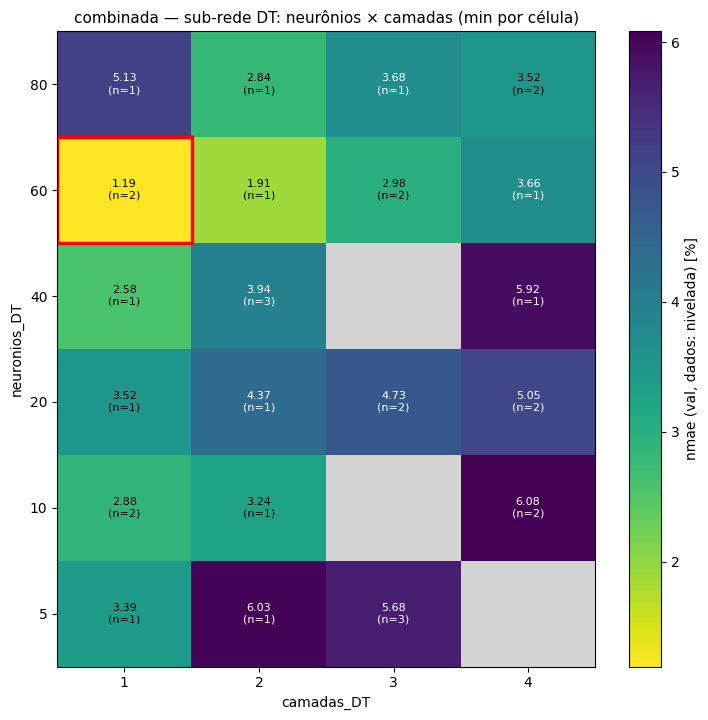

Melhor célula: neuronios_DT = 60, camadas_DT = 1 -> 1.194


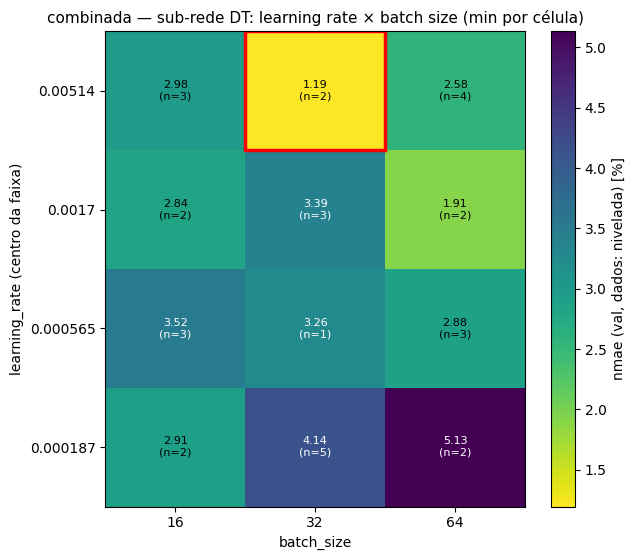

Melhor célula: learning_rate = 0.00514, batch_size = 32 -> 1.194


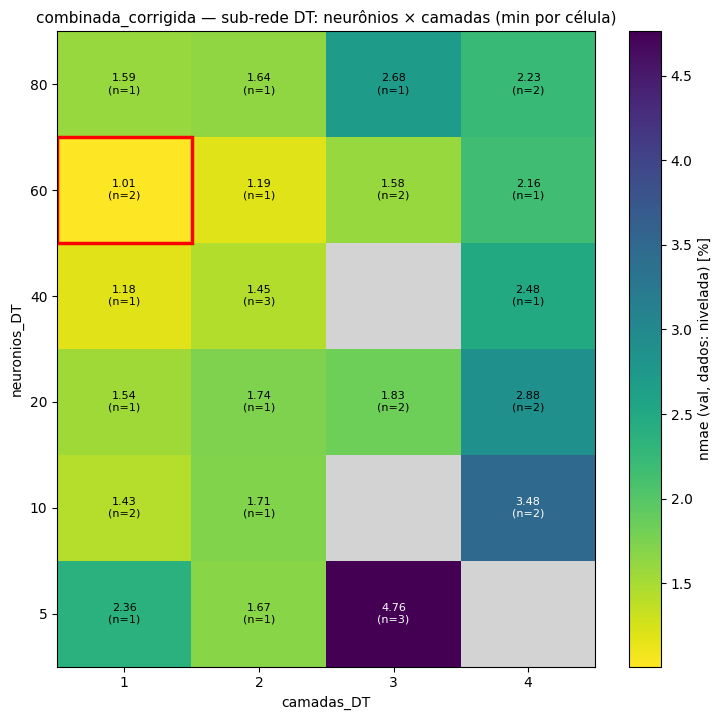

Melhor célula: neuronios_DT = 60, camadas_DT = 1 -> 1.008


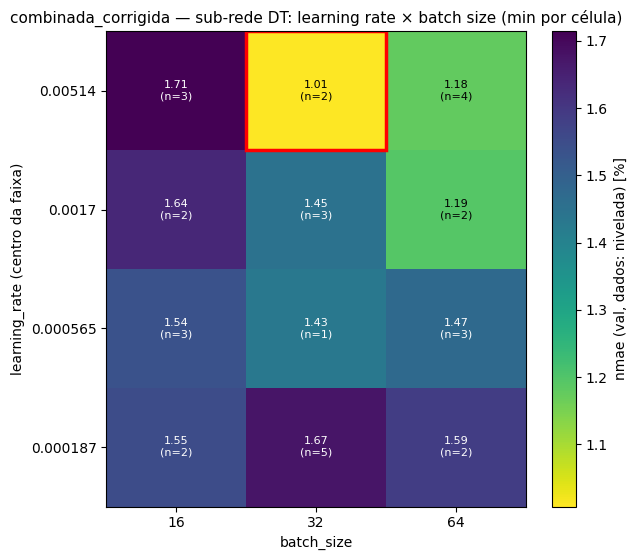

Melhor célula: learning_rate = 0.00514, batch_size = 32 -> 1.008


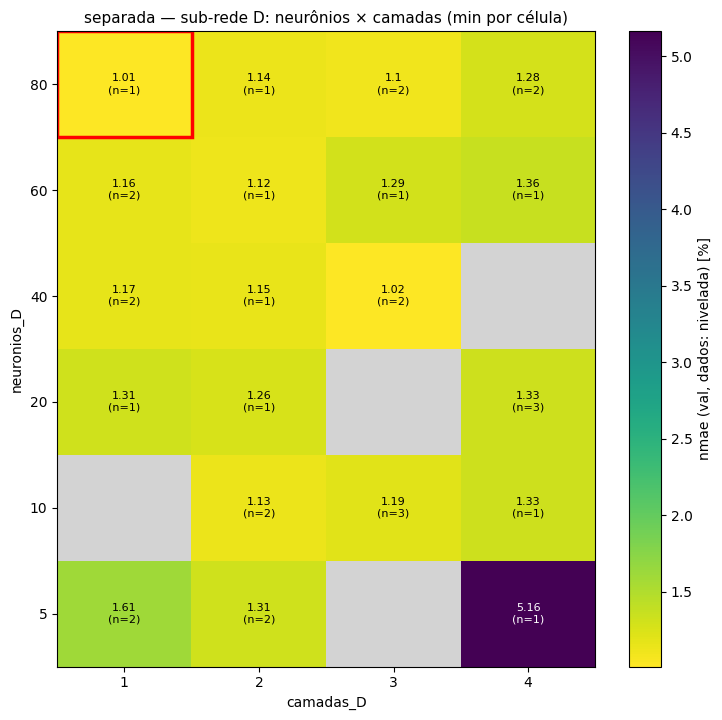

Melhor célula: neuronios_D = 80, camadas_D = 1 -> 1.01


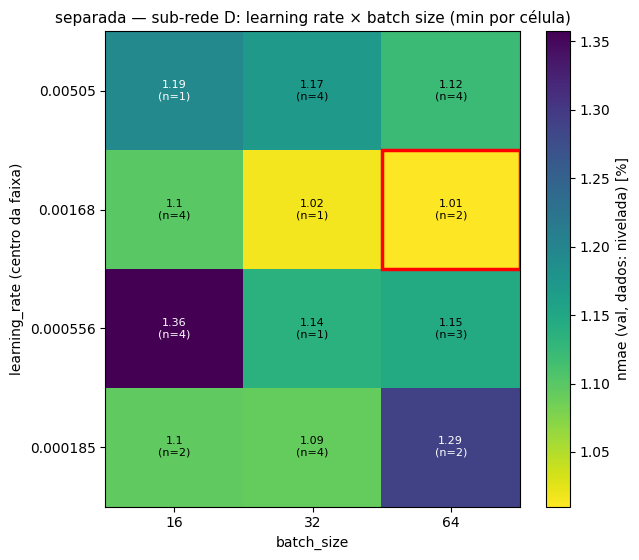

Melhor célula: learning_rate = 0.00168, batch_size = 64 -> 1.01


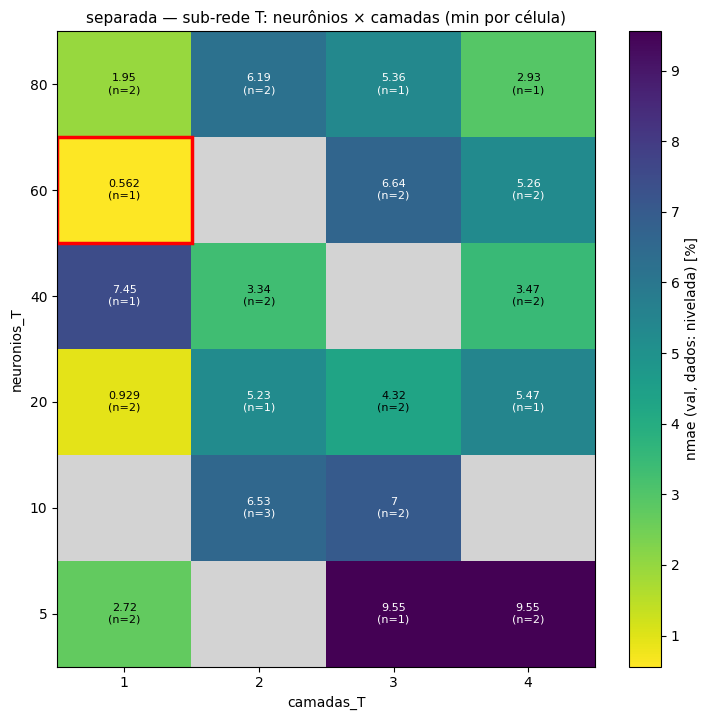

Melhor célula: neuronios_T = 60, camadas_T = 1 -> 0.5619


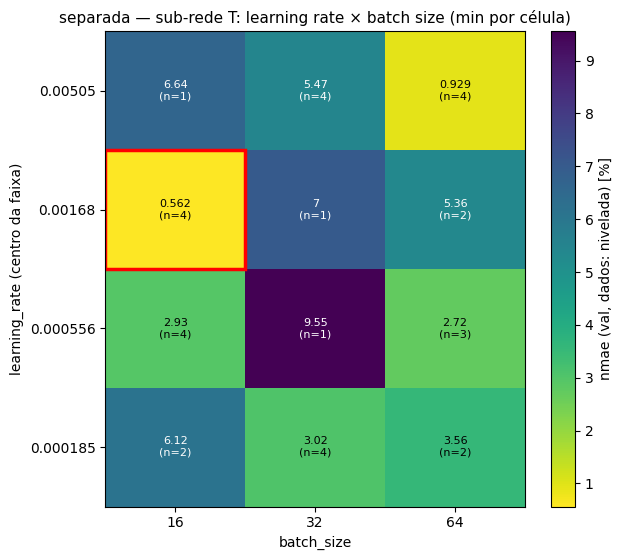

Melhor célula: learning_rate = 0.00168, batch_size = 16 -> 0.5619


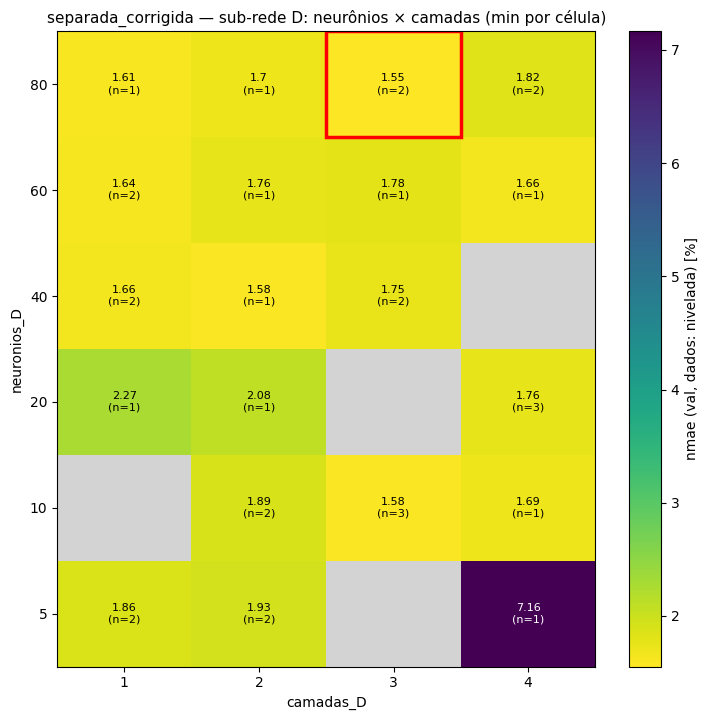

Melhor célula: neuronios_D = 80, camadas_D = 3 -> 1.553


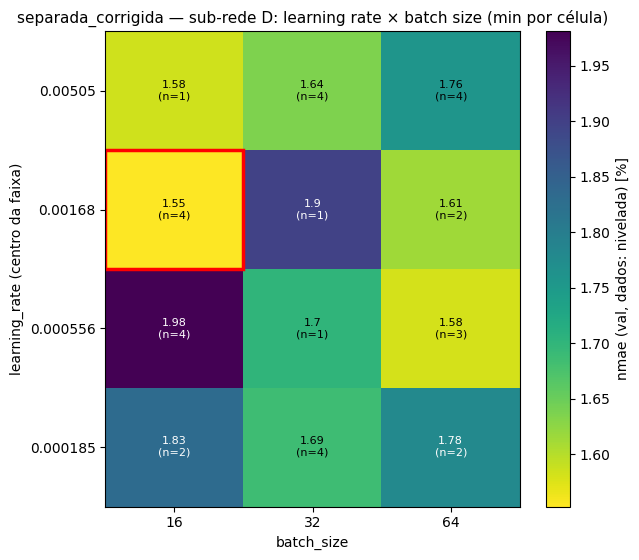

Melhor célula: learning_rate = 0.00168, batch_size = 16 -> 1.553


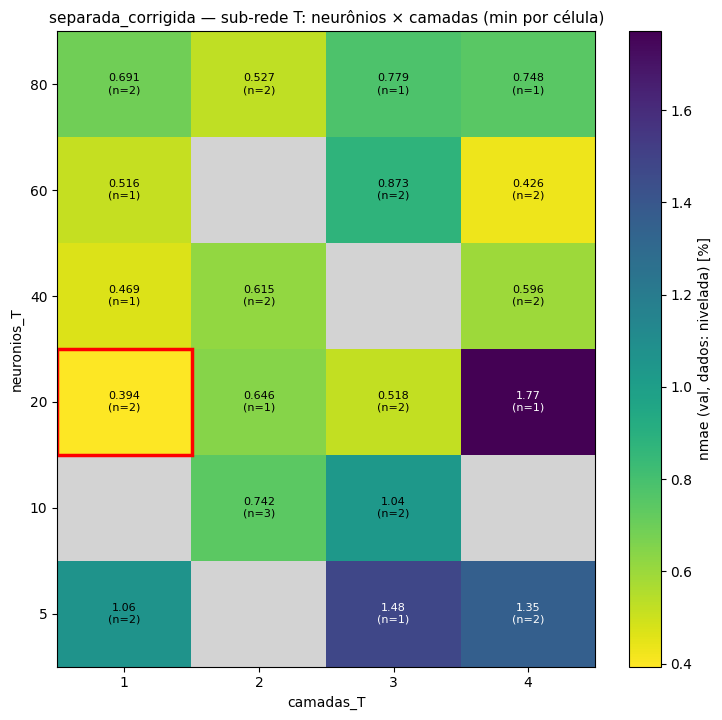

Melhor célula: neuronios_T = 20, camadas_T = 1 -> 0.3935


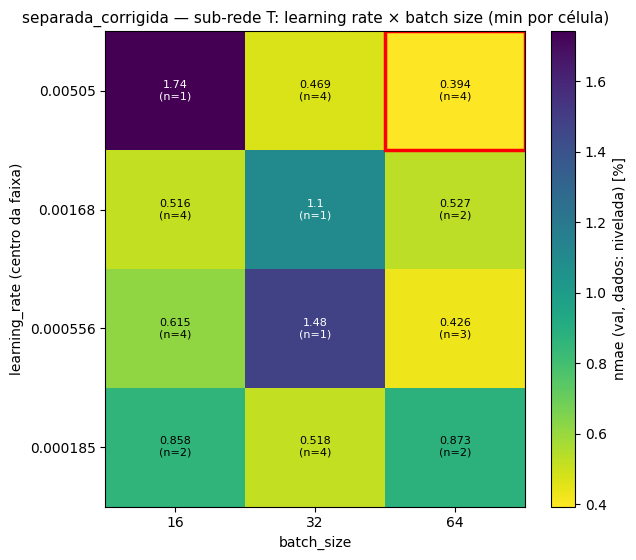

Melhor célula: learning_rate = 0.00505, batch_size = 64 -> 0.3935


In [25]:
# ---------------- Configuração ----------------
CSV_METRICAS = os.path.join(folder, 'metricas_lhs_todas.csv')
CONJUNTO     = 'val'
METRICA      = 'nmae'     # 'nmae' (% da faixa do target no treino), 'mape' (%), 'mae' ou 'rmse'.
                          # O score de um ramo é a média da métrica sobre os targets DELE (na combinada:
                          # CD e T juntos) -> use 'nmae' ou 'mape', que são adimensionais. No voo completo
                          # prefira 'nmae': D/δ e T passam perto de zero e o MAPE explode.
AGREGACAO    = 'min'      # como juntar configurações que caem na mesma célula: 'min' | 'mean' | 'median'
ESCALA_LOG   = False


# ---------------- Funções ----------------
def carregar_configuracoes(csv, conjunto, metrica):
    """Uma linha por (abordagem, ramo, ponto do LHS): score médio e desvio entre seeds.
    Cada ramo é avaliado só pelos seus targets: em D/T separados, o erro de T não depende da
    arquitetura de D (e vice-versa), então misturá-los só adicionaria ruído."""
    d = pd.read_csv(csv)
    d = d[d['conjunto'] == conjunto].dropna(subset=[metrica])
    hp_cols = [c for c in d.columns if c.startswith(('camadas_', 'neuronios_'))] + ['learning_rate', 'batch_size']
    por_seed = (d.groupby(['abordagem', 'ramo', 'lhs_id', 'seed'])[metrica]
                  .mean().rename('score').reset_index())
    cfg = (por_seed.groupby(['abordagem', 'ramo', 'lhs_id'])['score']
                   .agg(score='mean', desvio_seeds='std', n_seeds='count').reset_index())
    hp = d.drop_duplicates(['abordagem', 'lhs_id'])[['abordagem', 'lhs_id'] + hp_cols]
    return cfg.merge(hp, on=['abordagem', 'lhs_id'], how='left')


def _discretizar(serie, n_bins, log):
    """Agrupa um parâmetro contínuo em faixas; devolve o centro de cada faixa."""
    if serie.nunique() <= 1:
        return serie.astype(float)
    lo, hi = serie.min(), serie.max()
    bordas = np.geomspace(lo, hi, n_bins + 1) if log else np.linspace(lo, hi, n_bins + 1)
    cat = pd.cut(serie, bins=bordas, include_lowest=True)
    centros = np.sqrt(bordas[:-1] * bordas[1:]) if log else (bordas[:-1] + bordas[1:]) / 2
    mapa = dict(zip(cat.cat.categories, centros))
    return cat.map(mapa).astype(float)


def plotar_heatmap(cfg, eixo_y, eixo_x, agregacao='min', bins=None, escala_log=False,
                   rotulo_score='score', titulo=None, arquivo=None):
    bins = bins or {}
    d = cfg.copy()
    for col in (eixo_y, eixo_x):
        if col in bins:
            d[col] = _discretizar(d[col], bins[col], log=(col == 'learning_rate'))
    tab = d.pivot_table(index=eixo_y, columns=eixo_x, values='score', aggfunc=agregacao).sort_index()
    cont = d.pivot_table(index=eixo_y, columns=eixo_x, values='score', aggfunc='count').reindex_like(tab)

    Z = np.ma.masked_invalid(tab.values.astype(float))
    cmap = plt.get_cmap('viridis_r').copy()
    cmap.set_bad('lightgray')
    norm = LogNorm(vmin=np.nanmin(tab.values), vmax=np.nanmax(tab.values)) if escala_log else None

    fig, ax = plt.subplots(figsize=(1.0 * tab.shape[1] + 3.5, 0.8 * tab.shape[0] + 2.5))
    im = ax.imshow(Z, origin='lower', aspect='auto', cmap=cmap, norm=norm)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            if np.isnan(v):
                continue
            cor = 'white' if im.norm(v) > 0.5 else 'black'
            ax.text(j, i, f'{v:.3g}\n(n={int(cont.values[i, j])})', ha='center', va='center',
                    fontsize=8, color=cor)

    # contorno vermelho na melhor célula
    iy, ix = np.unravel_index(np.nanargmin(tab.values), tab.shape)
    ax.add_patch(Rectangle((ix - 0.5, iy - 0.5), 1, 1, fill=False, edgecolor='red', lw=2.5))

    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([f'{c:.3g}' for c in tab.columns])
    ax.set_yticks(range(tab.shape[0]))
    ax.set_yticklabels([f'{r:.3g}' for r in tab.index])
    ax.set_xlabel(eixo_x + (' (centro da faixa)' if eixo_x in bins else ''))
    ax.set_ylabel(eixo_y + (' (centro da faixa)' if eixo_y in bins else ''))
    ax.set_title(titulo or f'{rotulo_score} — {agregacao} por célula', fontsize=11)
    fig.colorbar(im, ax=ax, label=rotulo_score)
    fig.tight_layout()
    if arquivo:
        fig.savefig(arquivo, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Melhor célula: {eixo_y} = {tab.index[iy]:.3g}, {eixo_x} = {tab.columns[ix]:.3g} '
          f'-> {tab.values[iy, ix]:.4g}')
    return tab


# ---------------- Execução ----------------
cfg = carregar_configuracoes(CSV_METRICAS, CONJUNTO, METRICA)
print(f'{len(cfg)} combinações (abordagem, ramo, ponto LHS); '
      f'{cfg["n_seeds"].min()} a {cfg["n_seeds"].max()} seeds cada')
rotulo = f'{METRICA} ({CONJUNTO}, dados: {TIPO_DADOS or "nivelada"})' + (' [%]' if METRICA in ('mape', 'nmae') else '')

tabs = {}
for (chave, ramo), c in cfg.groupby(['abordagem', 'ramo']):
    pasta_saida = os.path.join(folder, chave)
    tabs[(chave, ramo, 'arquitetura')] = plotar_heatmap(
        c, eixo_y=f'neuronios_{ramo}', eixo_x=f'camadas_{ramo}',
        agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
        titulo=f'{chave} — sub-rede {ramo}: neurônios × camadas ({AGREGACAO} por célula)',
        arquivo=os.path.join(pasta_saida, f'heatmap_neuronios_camadas_{ramo}_{CONJUNTO}.png'),
    )
    tabs[(chave, ramo, 'treino')] = plotar_heatmap(
        c, eixo_y='learning_rate', eixo_x='batch_size', bins={'learning_rate': 4},
        agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
        titulo=f'{chave} — sub-rede {ramo}: learning rate × batch size ({AGREGACAO} por célula)',
        arquivo=os.path.join(pasta_saida, f'heatmap_lr_batch_{ramo}_{CONJUNTO}.png'),
    )

combinada / DT: 1 camadas x 60 neurônios | lhs_id = 8 | score = 1.194 | desvio_seeds = 0.2508 | n_seeds = 3 | n_configs = 32 | learning_rate = 0.008921 | batch_size = 32
combinada_corrigida / DT: 1 camadas x 60 neurônios | lhs_id = 8 | score = 1.008 | desvio_seeds = 0.277 | n_seeds = 3 | n_configs = 32 | learning_rate = 0.008921 | batch_size = 32
separada / D: 1 camadas x 80 neurônios | lhs_id = 3 | score = 1.01 | desvio_seeds = 0.16 | n_seeds = 3 | n_configs = 32 | learning_rate = 0.002636 | batch_size = 64
separada / T: 1 camadas x 60 neurônios | lhs_id = 14 | score = 0.5619 | desvio_seeds = 0.3596 | n_seeds = 3 | n_configs = 32 | learning_rate = 0.001756 | batch_size = 16
separada_corrigida / D: 3 camadas x 80 neurônios | lhs_id = 23 | score = 1.553 | desvio_seeds = 0.2777 | n_seeds = 3 | n_configs = 32 | learning_rate = 0.001943 | batch_size = 16
separada_corrigida / T: 1 camadas x 20 neurônios | lhs_id = 31 | score = 0.3935 | desvio_seeds = 0.1623 | n_seeds = 3 | n_configs = 32 | 

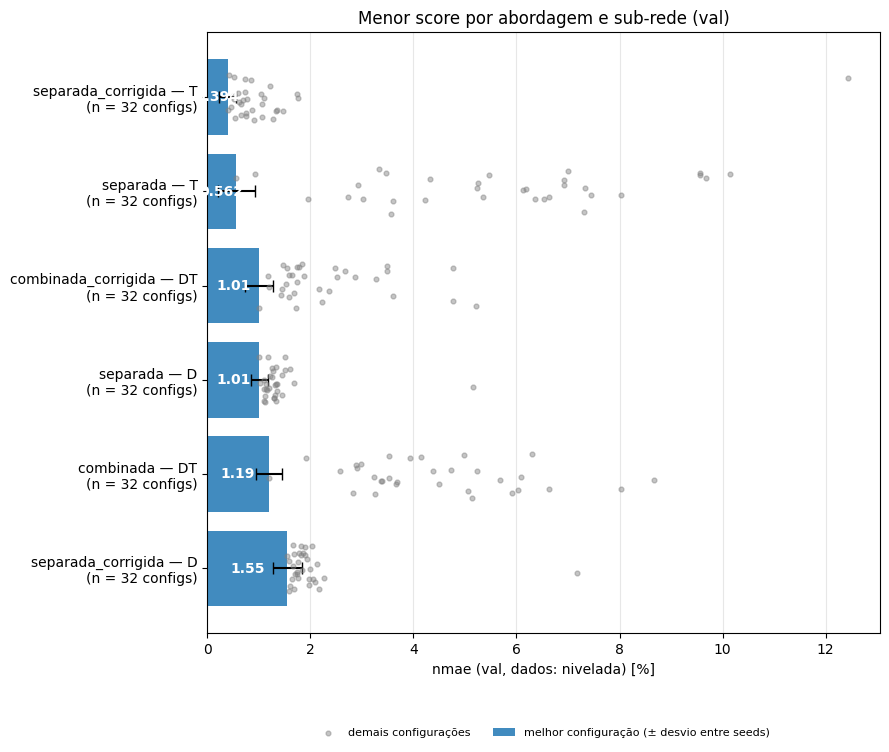

In [26]:
# Usa cfg, CSV_METRICAS, CONJUNTO e METRICA da célula anterior.
# Em D/T separados, a melhor sub-rede de D e a melhor de T são escolhidas de forma independente
# (podem vir de pontos diferentes do LHS), já que uma não afeta o erro da outra.
d_all = pd.read_csv(CSV_METRICAS)

melhores = cfg.loc[cfg.groupby(['abordagem', 'ramo'])['score'].idxmin()].reset_index(drop=True)
melhores['n_configs'] = melhores.apply(
    lambda m: int(((cfg['abordagem'] == m['abordagem']) & (cfg['ramo'] == m['ramo'])).sum()), axis=1)

# Métricas por target da melhor configuração de cada ramo (média entre seeds), em validação e teste
sel = d_all.merge(melhores[['abordagem', 'ramo', 'lhs_id']], on=['abordagem', 'ramo', 'lhs_id'])
tabela = (sel.groupby(['abordagem', 'ramo', 'target', 'conjunto'])[['nmae', 'mape', 'mpe', 'mae']]
             .mean().unstack('conjunto'))
tabela.columns = [f'{met}_{conj}' for met, conj in tabela.columns]

colunas_hp = ['lhs_id', 'score', 'desvio_seeds', 'n_seeds', 'n_configs', 'learning_rate', 'batch_size']
for _, m in melhores.iterrows():
    ramo = m['ramo']
    camadas, neuronios = int(m['camadas_' + ramo]), int(m['neuronios_' + ramo])
    print(f"{m['abordagem']} / {ramo}: {camadas} camadas x {neuronios} neurônios | "
          + ' | '.join(f'{c} = {m[c]:.4g}' for c in colunas_hp))
print()
print(tabela.round(4).to_string())
tabela.to_csv(os.path.join(folder, f'melhor_por_ramo_{CONJUNTO}.csv'))

# ---------------- Gráfico: melhor configuração de cada ramo ----------------
melhores = melhores.sort_values('score').reset_index(drop=True)
y = np.arange(len(melhores))
rotulos = [f"{m['abordagem']} — {m['ramo']}\n(n = {m['n_configs']} configs)" for _, m in melhores.iterrows()]

fig, ax = plt.subplots(figsize=(9, 0.9 * len(melhores) + 2.2))
ax.barh(y, melhores['score'], xerr=melhores['desvio_seeds'].fillna(0), color='tab:blue', alpha=0.85,
        capsize=4, zorder=2, label='melhor configuração (± desvio entre seeds)')
rng = np.random.RandomState(0)
for yi, (_, m) in zip(y, melhores.iterrows()):
    s = cfg.loc[(cfg['abordagem'] == m['abordagem']) & (cfg['ramo'] == m['ramo']), 'score'].to_numpy()
    ax.scatter(s, yi + rng.uniform(-0.25, 0.25, len(s)), s=12, color='gray', alpha=0.45, zorder=3,
               label='demais configurações' if yi == 0 else None)
for yi, v in zip(y, melhores['score']):
    ax.text(v / 2, yi, f'{v:.3g}', ha='center', va='center', color='white', fontweight='bold', zorder=4)
ax.set_yticks(y)
ax.set_yticklabels(rotulos)
ax.invert_yaxis()                      # melhor no topo
ax.set_xlabel(rotulo)
ax.set_title(f'Menor score por abordagem e sub-rede ({CONJUNTO})')
ax.grid(axis='x', alpha=0.3, zorder=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(folder, f'menor_score_por_ramo_{CONJUNTO}.png'), dpi=150, bbox_inches='tight')
plt.show()

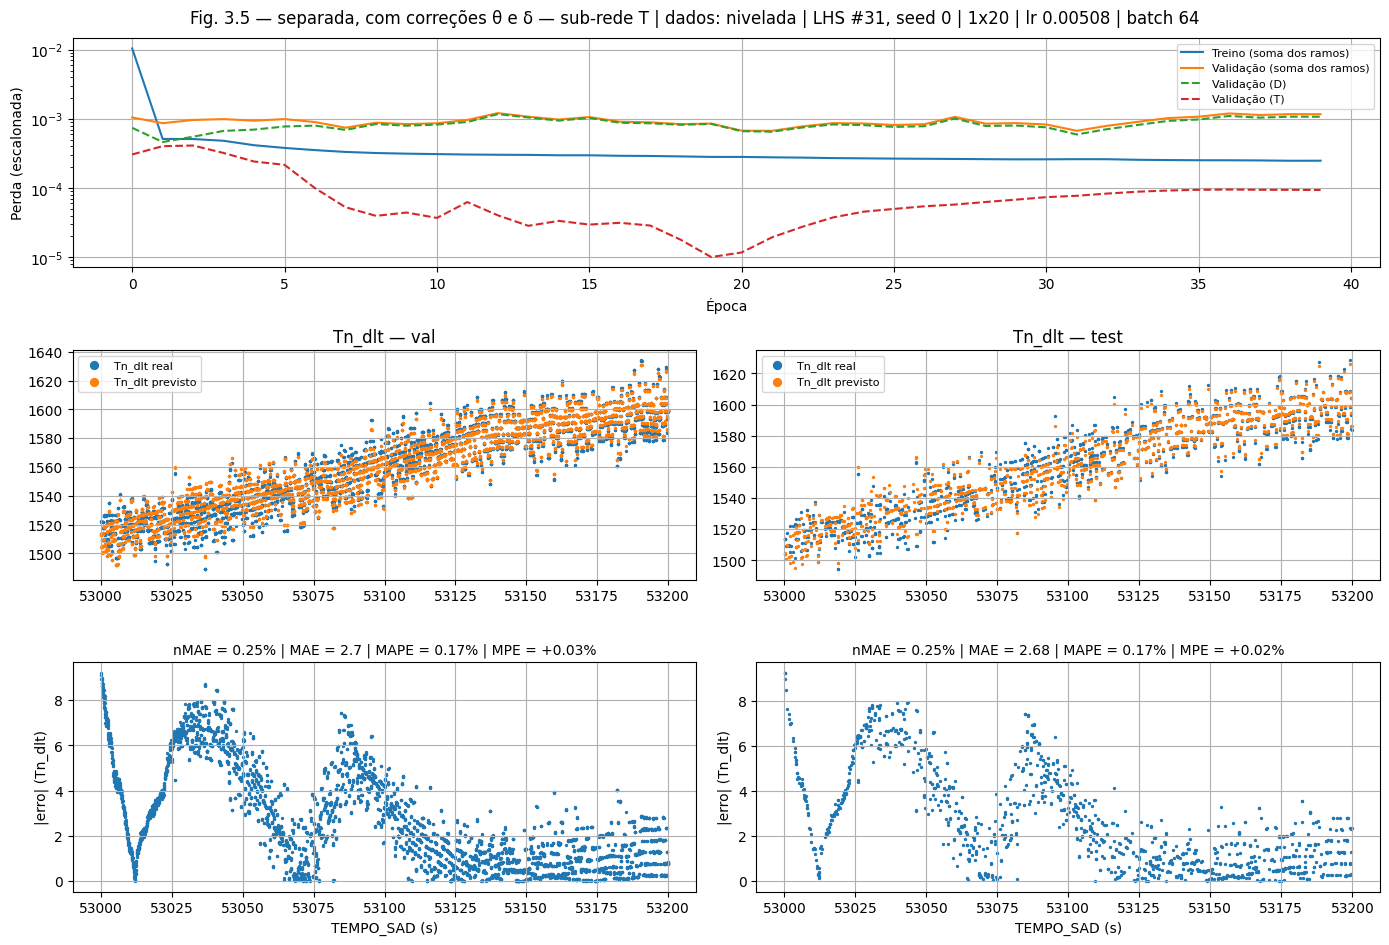

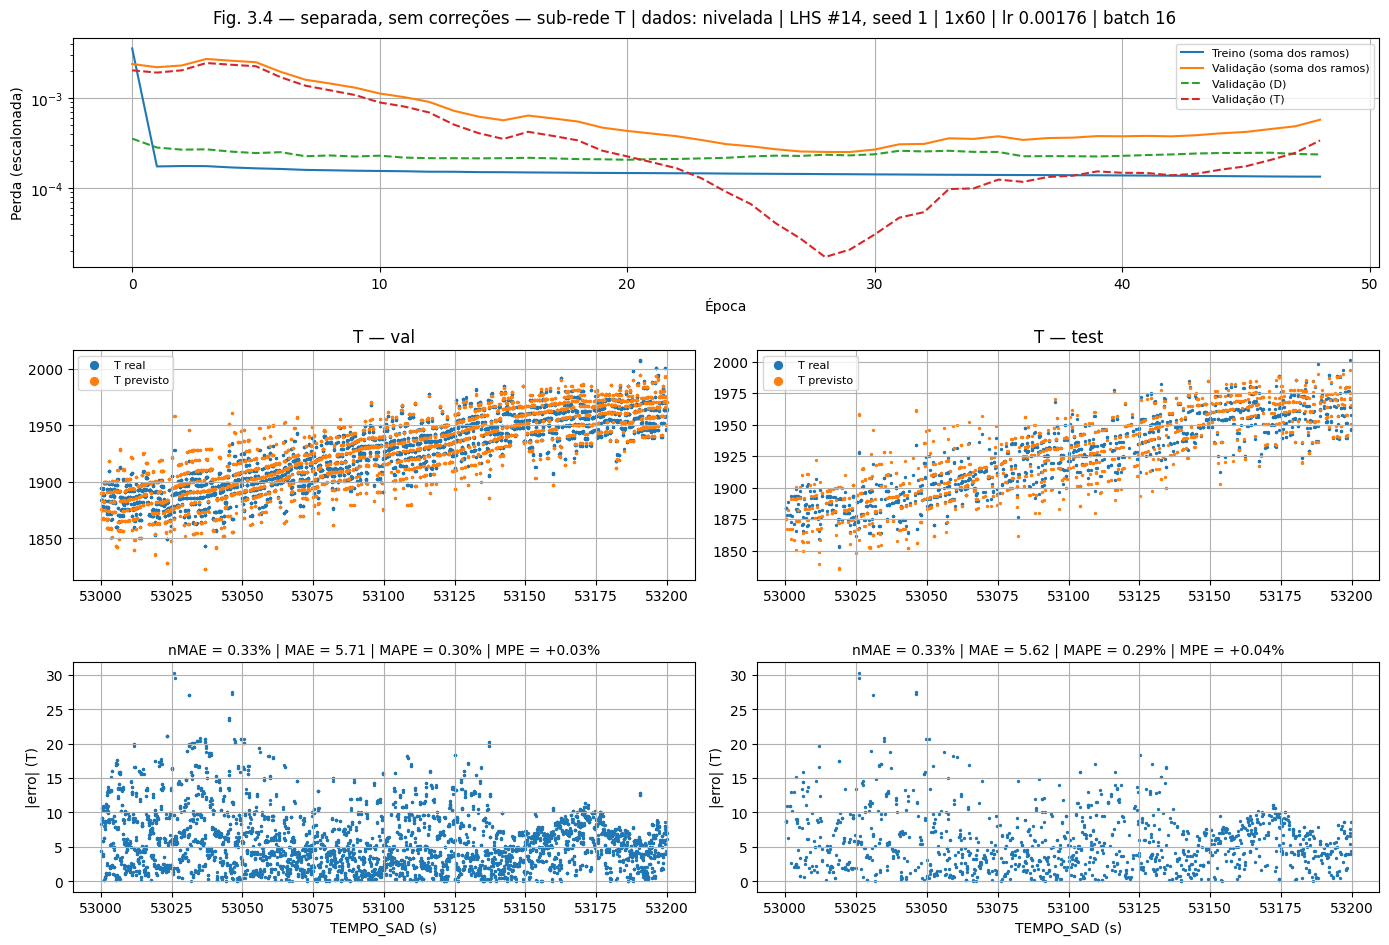

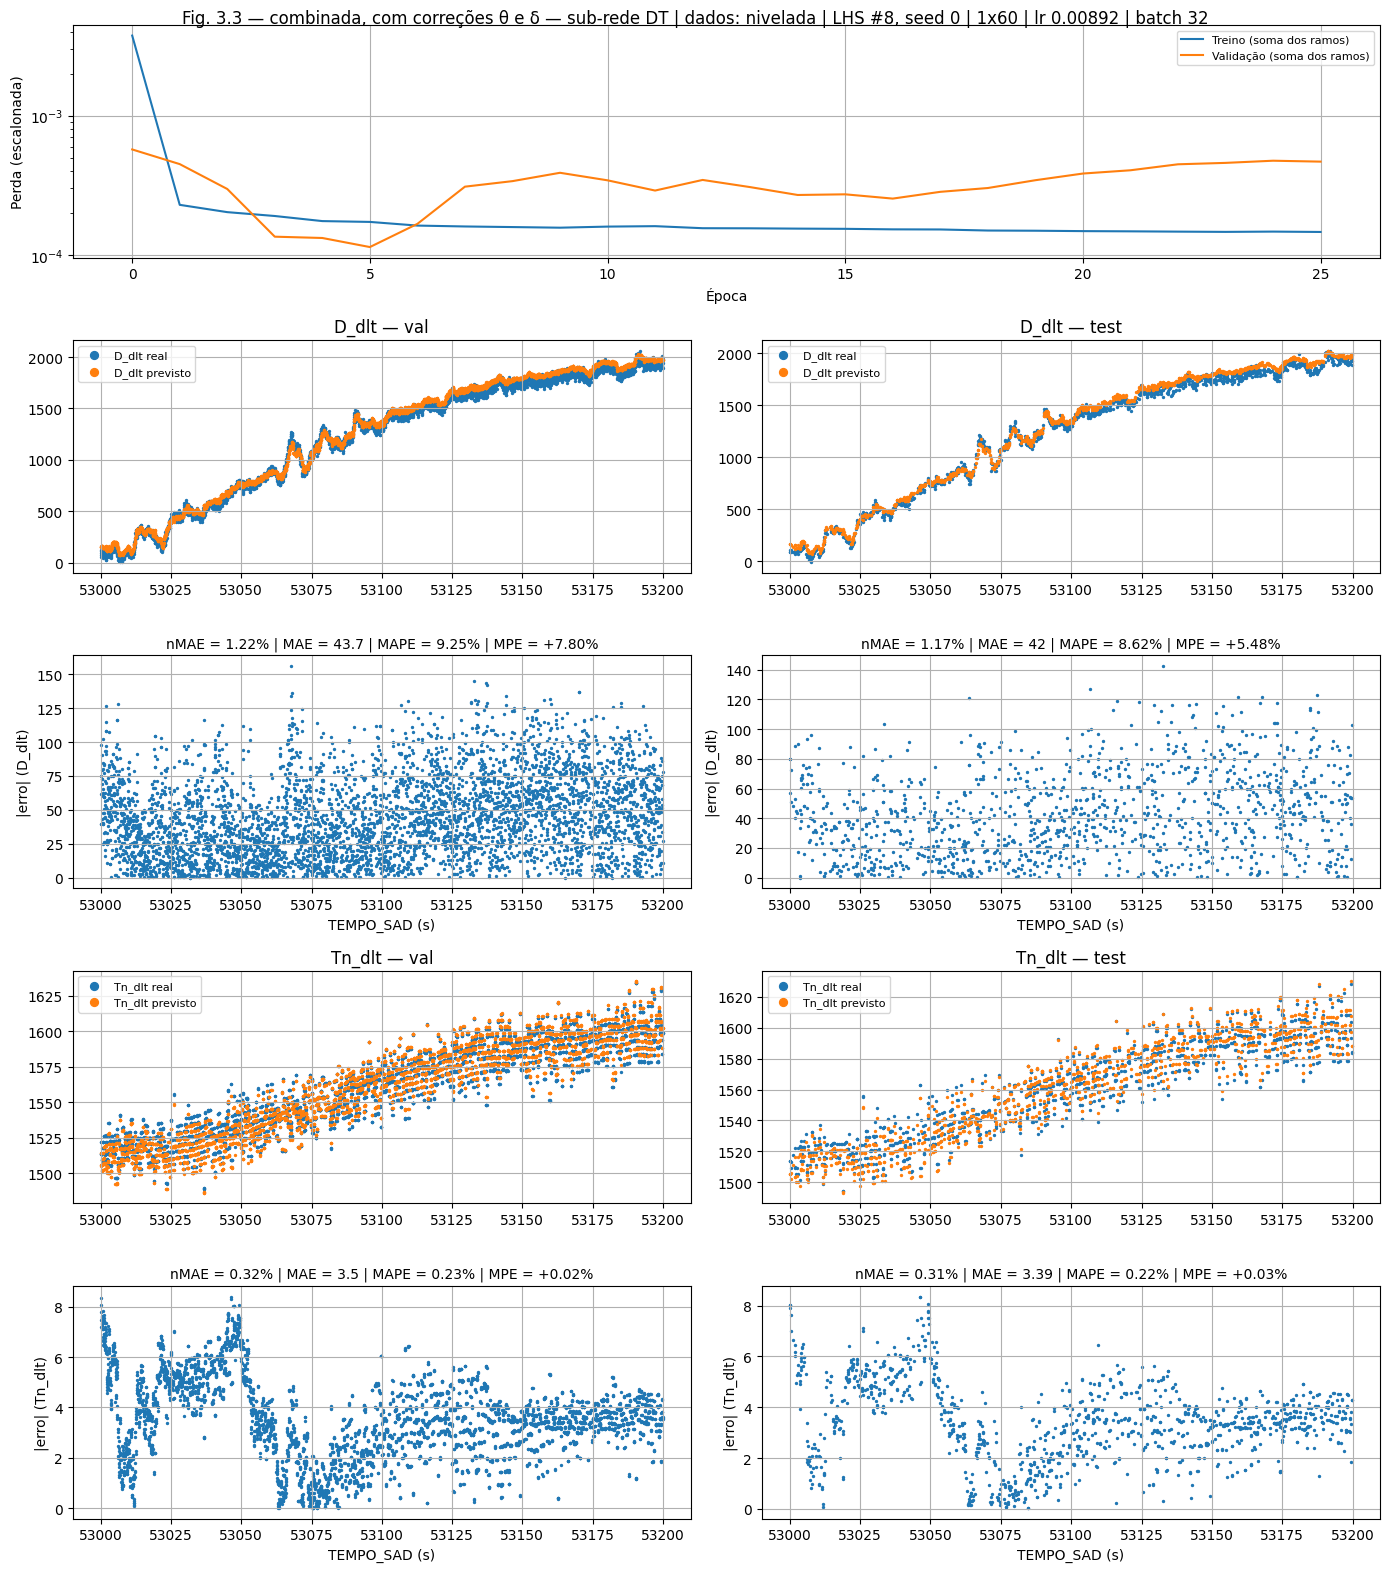

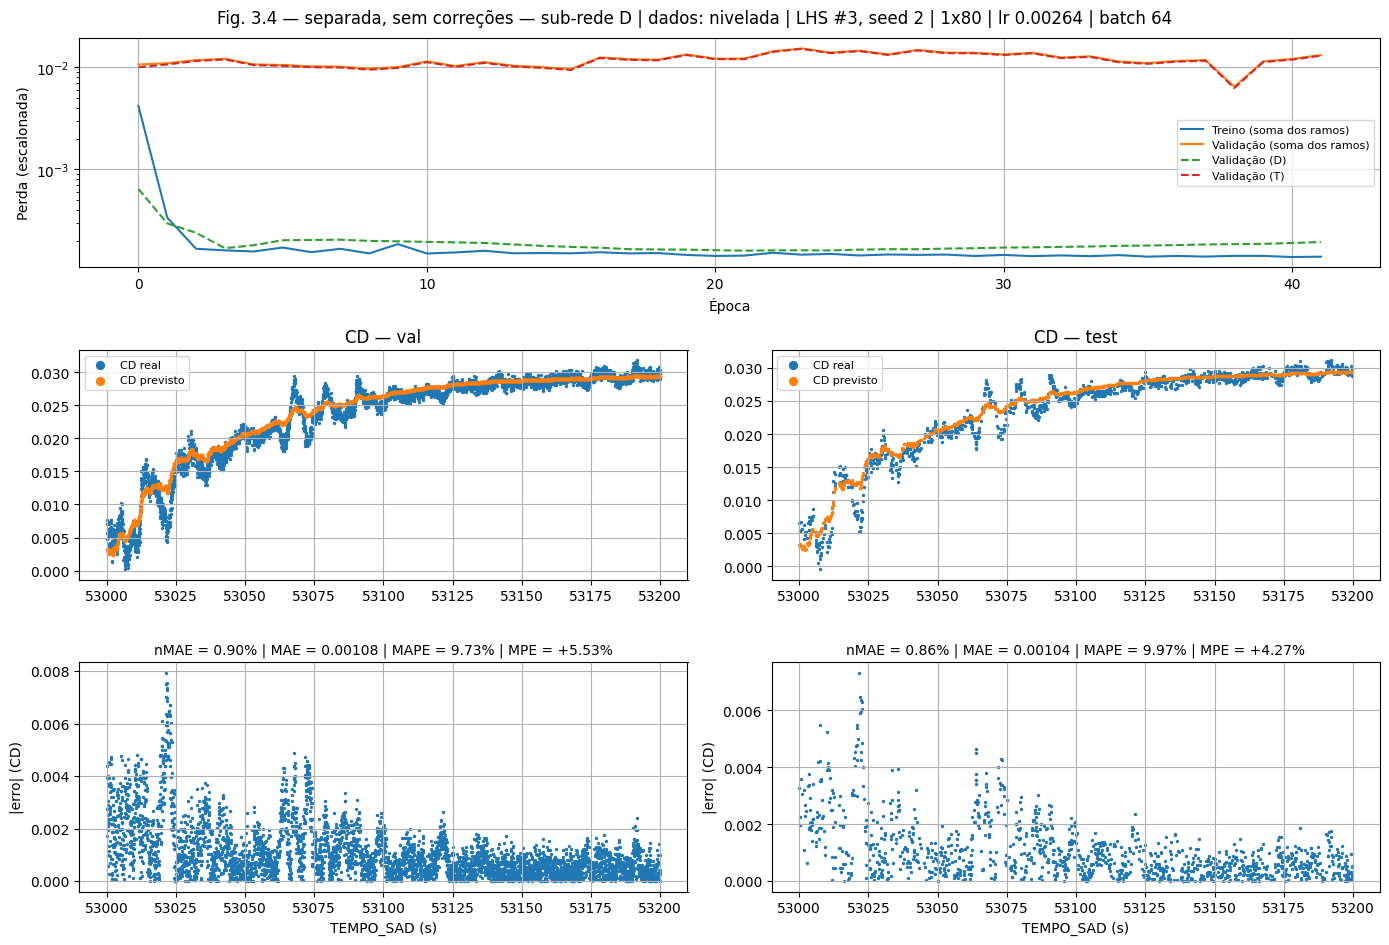

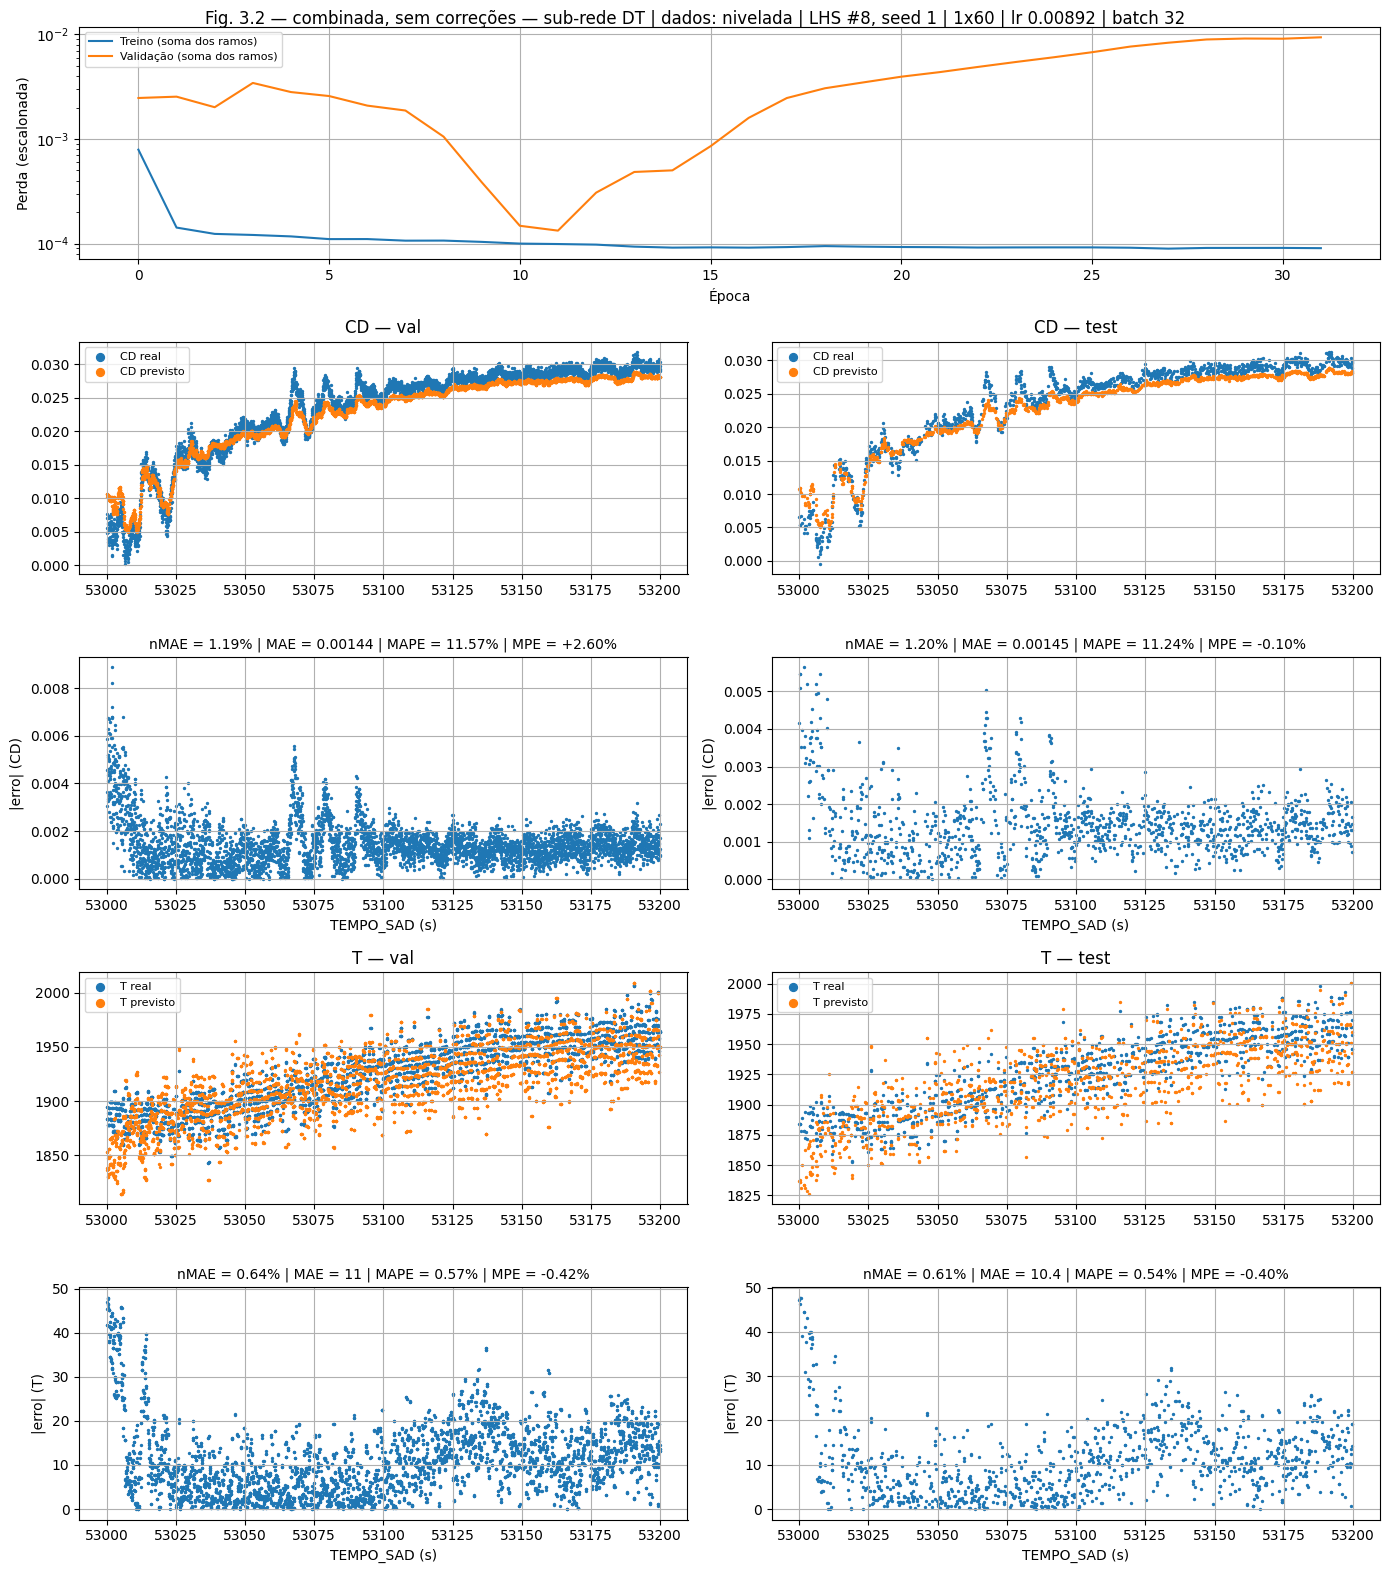

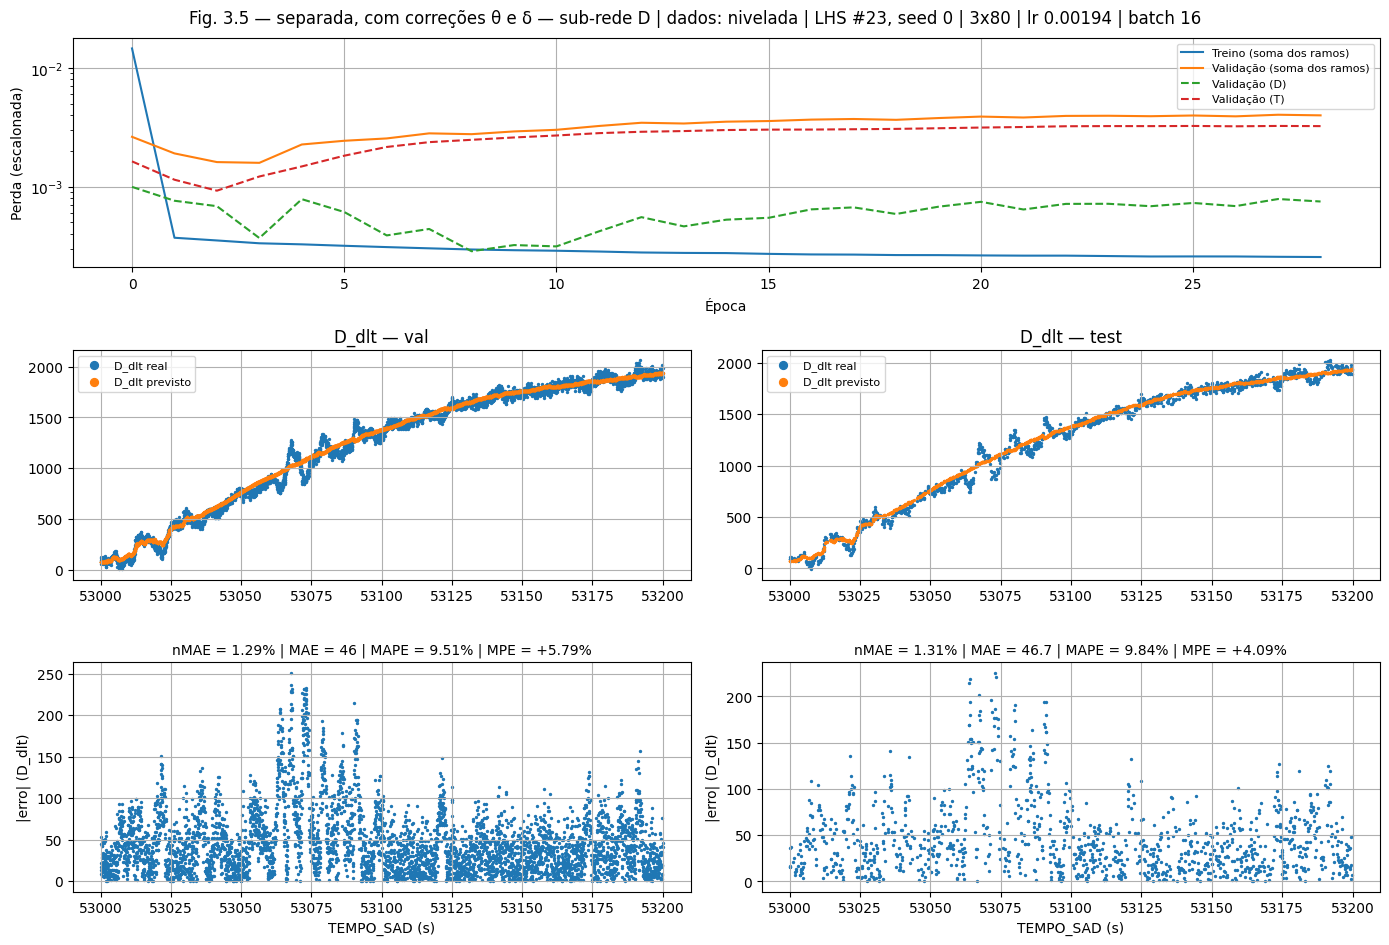

In [27]:
# Recarrega, para cada abordagem e sub-rede, a rede da melhor configuração (substitui o retreino
# manual com os melhores hiperparâmetros). Entre as seeds dessa configuração, mostra a de menor erro
# em CONJUNTO — só para visualização; a tabela acima usa a média entre seeds.
def recarregar_rede(chave, lhs_id, seed):
    combo_dir = os.path.join(folder, chave, 'redes', f's{seed}_lhs{lhs_id:03d}')
    model, hist, scalers, config, metricas_combo = carregar_checkpoint(combo_dir)
    df = preparar_df(config['tipo_dados'], config['ramos'])   # mesmos dados e mesmo descarte de NaN do treino
    for col, scaler in scalers.items():          # scalers SALVOS (ajustados no treino), sem novo fit
        df[col + '_scaled'] = scaler.transform(df[[col]]).ravel().astype(np.float32)
    df = prever(model, df, config['ramos'], scalers)
    return df, model, hist, config, metricas_combo


melhores_redes = {}
for _, m in melhores.iterrows():
    chave, ramo, lhs_id = m['abordagem'], m['ramo'], int(m['lhs_id'])
    linhas = d_all[(d_all['abordagem'] == chave) & (d_all['ramo'] == ramo) &
                   (d_all['lhs_id'] == lhs_id) & (d_all['conjunto'] == CONJUNTO)]
    seed = int(linhas.groupby('seed')[METRICA].mean().idxmin())

    df_b, model_b, hist_b, config_b, met_b = recarregar_rede(chave, lhs_id, seed)
    ramo_b = [r for r in config_b['ramos'] if r['nome'] == ramo]
    arq_b = config_b['architecture']
    figura_resultados(
        df_b, ramo_b, hist_b, met_b.to_dict('records'),
        titulo=(f"{ABORDAGENS[chave]['nome']} — sub-rede {ramo} | dados: {config_b['tipo_dados'] or 'nivelada'} | "
                f"LHS #{lhs_id}, seed {seed} | "
                f"{arq_b[f'camadas_ocultas_{ramo}']}x{arq_b[f'neurons_{ramo}']} | "
                f"lr {config_b['hyperparameters']['learning_rate']:.3g} | "
                f"batch {config_b['hyperparameters']['batch_size']}"),
    )
    plt.show()
    melhores_redes[(chave, ramo)] = (df_b, model_b, hist_b, config_b, met_b)